In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# import glob
# import os

# folder_path = "flight_data_2024"

# csv_files = glob.glob(os.path.join(folder_path, "*.csv"))

# print("Number of CSV files found:", len(csv_files))

# if len(csv_files) != 12:
#     raise ValueError("Please check that all 12 monthly CSV files are present.")

# dataframes = []

# for file in csv_files:
#     print("Reading:", os.path.basename(file))
#     month_df = pd.read_csv(file, low_memory=False)
#     dataframes.append(month_df)

# df = pd.concat(dataframes, ignore_index=True)

# print("\nCombined dataset shape:", df.shape)
# print("Number of duplicate rows:", df.duplicated().sum())

# df.to_csv("flight_data_2024.csv", index=False)

# print("\nSaved as flight_data_2024.csv")
# #output
# # Number of CSV files found: 12
# # Reading: apr.csv
# # Reading: aug.csv
# # Reading: dec.csv
# # Reading: feb.csv
# # Reading: jan.csv
# # Reading: jul.csv
# # Reading: jun.csv
# # Reading: mar.csv
# # Reading: may.csv
# # Reading: nov.csv
# # Reading: oct.csv
# # Reading: sep.csv

# # Combined dataset shape: (7079061, 110)
# # Number of duplicate rows: 0

# # Saved as flight_data_2024.csv


In [3]:
# Read the already-generated annual CSV
df = pd.read_csv("flight_data_2024.csv", low_memory=False)

# Convert FlightDate to datetime
df["FlightDate"] = pd.to_datetime(df["FlightDate"])

# Sort the dataset chronologically
df = df.sort_values(by="FlightDate").reset_index(drop=True)

# Save the sorted dataset
df.to_csv("flight_data_2024.csv", index=False)

# Verify
print("Dataset shape:", df.shape)
print("Earliest date:", df["FlightDate"].min())
print("Latest date:", df["FlightDate"].max())

print("\nFlights per month:")
print(df.groupby("Month").size().sort_index())

Dataset shape: (1221587, 110)
Earliest date: 2024-01-01 00:00:00
Latest date: 2024-03-09 00:00:00

Flights per month:
Month
1    547271
2    519221
3    155095
dtype: int64


In [4]:
empty_columns = df.columns[df.isnull().all()].tolist()

print("Number of completely empty columns:", len(empty_columns))
print("\nCompletely empty columns:")
print(empty_columns)

Number of completely empty columns: 17

Completely empty columns:
['Div4Airport', 'Div4AirportID', 'Div4AirportSeqID', 'Div4WheelsOn', 'Div4TotalGTime', 'Div4LongestGTime', 'Div4WheelsOff', 'Div4TailNum', 'Div5Airport', 'Div5AirportID', 'Div5AirportSeqID', 'Div5WheelsOn', 'Div5TotalGTime', 'Div5LongestGTime', 'Div5WheelsOff', 'Div5TailNum', 'Unnamed: 109']


In [5]:
missing_count = df.isnull().sum()

missing_percentage = (missing_count / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values(by="Missing Percentage", ascending=False)

print(missing_summary.to_string())

                      Missing Count  Missing Percentage
Div5Airport                 1221587          100.000000
Div4TailNum                 1221587          100.000000
Div4WheelsOff               1221587          100.000000
Div4LongestGTime            1221587          100.000000
Div4TotalGTime              1221587          100.000000
Div4WheelsOn                1221587          100.000000
Div4AirportSeqID            1221587          100.000000
Div4AirportID               1221587          100.000000
Div4Airport                 1221587          100.000000
Div5AirportSeqID            1221587          100.000000
Div5WheelsOn                1221587          100.000000
Div5TotalGTime              1221587          100.000000
Div5LongestGTime            1221587          100.000000
Div5WheelsOff               1221587          100.000000
Div5TailNum                 1221587          100.000000
Unnamed: 109                1221587          100.000000
Div5AirportID               1221587          100

In [6]:
# Calculate missing-value percentage for each column
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Select columns with more than 50% missing values
columns_to_drop = missing_percentage[missing_percentage > 50].index.tolist()

# Display columns before deleting
print("Number of columns to delete:", len(columns_to_drop))
print("\nColumns to delete:")
print(columns_to_drop)

# Delete the selected columns
df.drop(columns=columns_to_drop, inplace=True)

# Display the updated dataset shape
print("\nDataset shape after deletion:", df.shape)

# Verify that no columns have more than 50% missing values
remaining_missing_percentage = (df.isnull().sum() / len(df)) * 100

print(
    "\nRemaining columns with more than 50% missing values:",
    remaining_missing_percentage[remaining_missing_percentage > 50].index.tolist()
)

Number of columns to delete: 54

Columns to delete:
['CancellationCode', 'CarrierDelay', 'WeatherDelay', 'NASDelay', 'SecurityDelay', 'LateAircraftDelay', 'FirstDepTime', 'TotalAddGTime', 'LongestAddGTime', 'DivReachedDest', 'DivActualElapsedTime', 'DivArrDelay', 'DivDistance', 'Div1Airport', 'Div1AirportID', 'Div1AirportSeqID', 'Div1WheelsOn', 'Div1TotalGTime', 'Div1LongestGTime', 'Div1WheelsOff', 'Div1TailNum', 'Div2Airport', 'Div2AirportID', 'Div2AirportSeqID', 'Div2WheelsOn', 'Div2TotalGTime', 'Div2LongestGTime', 'Div2WheelsOff', 'Div2TailNum', 'Div3Airport', 'Div3AirportID', 'Div3AirportSeqID', 'Div3WheelsOn', 'Div3TotalGTime', 'Div3LongestGTime', 'Div3WheelsOff', 'Div3TailNum', 'Div4Airport', 'Div4AirportID', 'Div4AirportSeqID', 'Div4WheelsOn', 'Div4TotalGTime', 'Div4LongestGTime', 'Div4WheelsOff', 'Div4TailNum', 'Div5Airport', 'Div5AirportID', 'Div5AirportSeqID', 'Div5WheelsOn', 'Div5TotalGTime', 'Div5LongestGTime', 'Div5WheelsOff', 'Div5TailNum', 'Unnamed: 109']

Dataset shape 

In [7]:
# Calculate missing-value counts and percentages
missing_count = df.isnull().sum()
missing_percentage = (missing_count / len(df)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage
})

# Display only columns containing missing values
missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values(by="Missing Percentage", ascending=False)

print("Dataset shape:", df.shape)

print("\nRemaining columns with missing values:")
print(missing_summary.to_string())

print("\nTotal missing values:", df.isnull().sum().sum())

Dataset shape: (1221587, 56)

Remaining columns with missing values:
                      Missing Count  Missing Percentage
ArrDel15                      27582            2.257883
ArrivalDelayGroups            27582            2.257883
ArrDelayMinutes               27582            2.257883
ArrDelay                      27582            2.257883
ActualElapsedTime             27582            2.257883
AirTime                       27582            2.257883
WheelsOn                      25114            2.055850
TaxiIn                        25114            2.055850
ArrTime                       25112            2.055687
TaxiOut                       24483            2.004196
WheelsOff                     24483            2.004196
DepDelayMinutes               23968            1.962038
DepDelay                      23968            1.962038
DepartureDelayGroups          23968            1.962038
DepDel15                      23968            1.962038
DepTime                       23857

In [8]:

# Remove rows with missing target, cancelled flights and diverted flights

df = df.dropna(subset=["ArrDel15"])
df = df[(df["Cancelled"] == 0) & (df["Diverted"] == 0)]

print("Dataset shape after cleaning:", df.shape)
df.isnull().sum()

Dataset shape after cleaning: (1194005, 56)


Year                               0
Quarter                            0
Month                              0
DayofMonth                         0
DayOfWeek                          0
FlightDate                         0
Reporting_Airline                  0
DOT_ID_Reporting_Airline           0
IATA_CODE_Reporting_Airline        0
Tail_Number                        0
Flight_Number_Reporting_Airline    0
OriginAirportID                    0
OriginAirportSeqID                 0
OriginCityMarketID                 0
Origin                             0
OriginCityName                     0
OriginState                        0
OriginStateFips                    0
OriginStateName                    0
OriginWac                          0
DestAirportID                      0
DestAirportSeqID                   0
DestCityMarketID                   0
Dest                               0
DestCityName                       0
DestState                          0
DestStateFips                      0
D

In [9]:
df = df.dropna()
print("Dataset shape:", df.shape)
df.isnull().sum().sum()

Dataset shape: (1194005, 56)


np.int64(0)

Target distribution:
ArrDel15
0.0    954959
1.0    239046
Name: count, dtype: int64

Target percentage:
ArrDel15
0.0    79.98
1.0    20.02
Name: proportion, dtype: float64


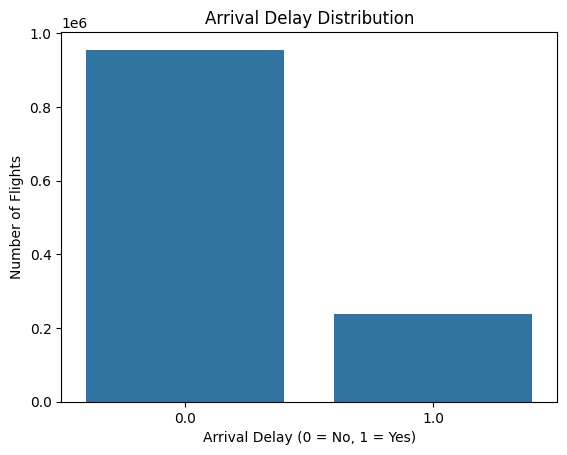

In [10]:
print("Target distribution:")
print(df["ArrDel15"].value_counts())

print("\nTarget percentage:")
print((df["ArrDel15"].value_counts(normalize=True) * 100).round(2))

sns.countplot(data=df, x="ArrDel15")
plt.title("Arrival Delay Distribution")
plt.xlabel("Arrival Delay (0 = No, 1 = Yes)")
plt.ylabel("Number of Flights")
plt.show()

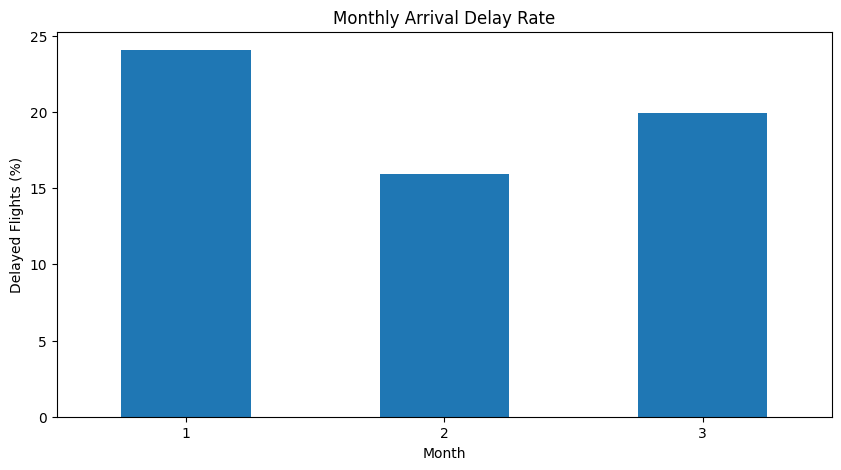

Month
1    24.06
2    15.92
3    19.95
Name: ArrDel15, dtype: float64


In [11]:
monthly_delay = df.groupby("Month")["ArrDel15"].mean() * 100

monthly_delay.plot(kind="bar", figsize=(10, 5))
plt.title("Monthly Arrival Delay Rate")
plt.xlabel("Month")
plt.ylabel("Delayed Flights (%)")
plt.xticks(rotation=0)
plt.show()

print(monthly_delay.round(2))

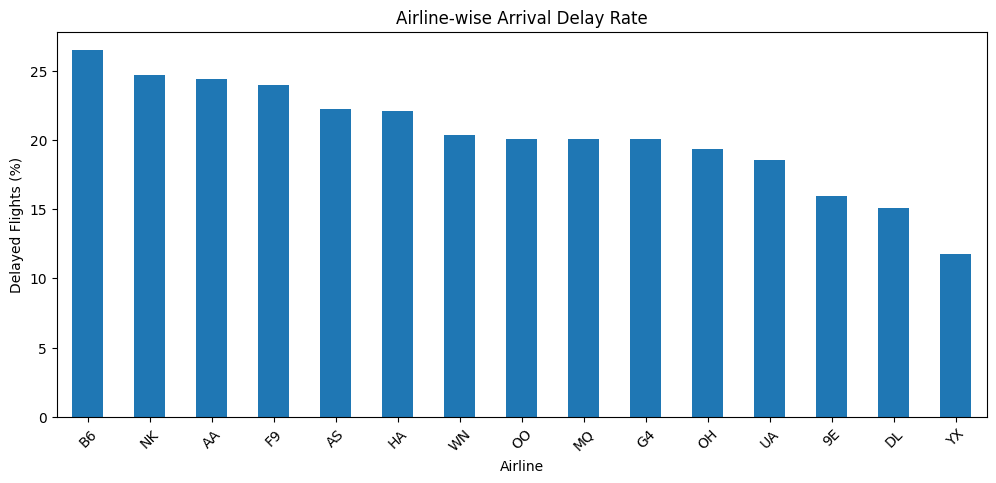

Reporting_Airline
B6    26.50
NK    24.74
AA    24.40
F9    24.01
AS    22.28
HA    22.07
WN    20.37
OO    20.09
MQ    20.08
G4    20.07
OH    19.33
UA    18.54
9E    15.98
DL    15.07
YX    11.74
Name: ArrDel15, dtype: float64


In [12]:
airline_delay = df.groupby("Reporting_Airline")["ArrDel15"].mean() * 100

airline_delay.sort_values(ascending=False).plot(
    kind="bar", figsize=(12, 5)
)

plt.title("Airline-wise Arrival Delay Rate")
plt.xlabel("Airline")
plt.ylabel("Delayed Flights (%)")
plt.xticks(rotation=45)
plt.show()

print(airline_delay.sort_values(ascending=False).round(2))

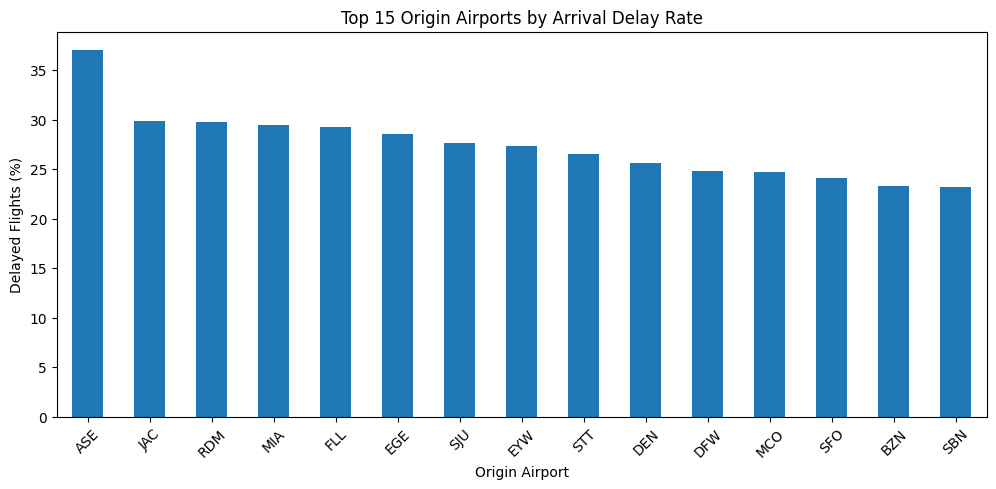

         mean  count
Origin              
ASE     37.03   1939
JAC     29.91   1187
RDM     29.76   1055
MIA     29.51  22132
FLL     29.26  18619
EGE     28.60   1388
SJU     27.69   6320
EYW     27.32   1841
STT     26.58   1189
DEN     25.61  50357
DFW     24.81  51986
MCO     24.76  31328
SFO     24.10  21796
BZN     23.31   1845
SBN     23.24   1093


In [13]:
origin_delay = df.groupby("Origin")["ArrDel15"].agg(["mean", "count"])

origin_delay = origin_delay[origin_delay["count"] >= 1000]
origin_delay["mean"] = origin_delay["mean"] * 100

top_origin = origin_delay.sort_values("mean", ascending=False).head(15)

top_origin["mean"].plot(kind="bar", figsize=(12, 5))

plt.title("Top 15 Origin Airports by Arrival Delay Rate")
plt.xlabel("Origin Airport")
plt.ylabel("Delayed Flights (%)")
plt.xticks(rotation=45)
plt.show()

print(top_origin.round(2))

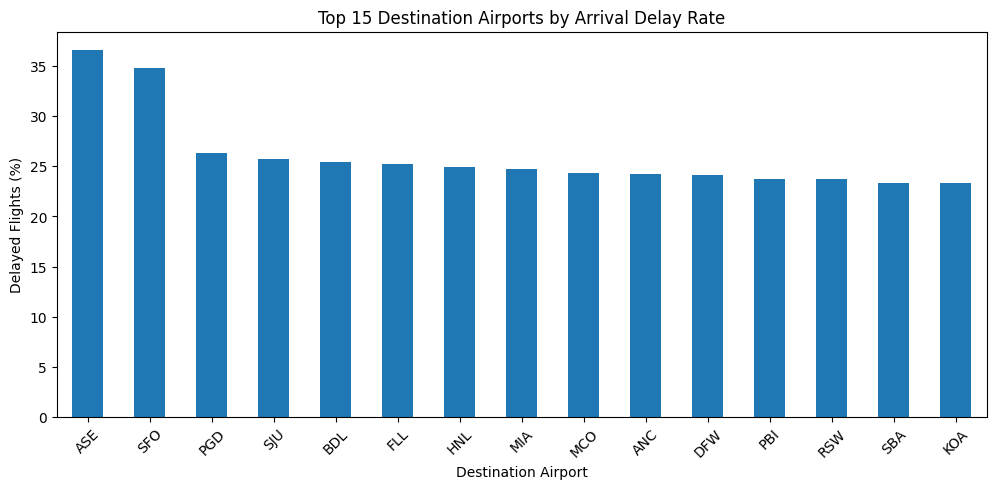

       mean  count
Dest              
ASE   36.61   1915
SFO   34.79  21755
PGD   26.32   1288
SJU   25.77   6334
BDL   25.45   3595
FLL   25.27  18576
HNL   24.93  11032
MIA   24.77  22152
MCO   24.31  31374
ANC   24.25   2392
DFW   24.16  52015
PBI   23.77   6402
RSW   23.73   8590
SBA   23.34   1161
KOA   23.31   2934


In [14]:
dest_delay = df.groupby("Dest")["ArrDel15"].agg(["mean", "count"])

dest_delay = dest_delay[dest_delay["count"] >= 1000]
dest_delay["mean"] = dest_delay["mean"] * 100

top_dest = dest_delay.sort_values("mean", ascending=False).head(15)

top_dest["mean"].plot(kind="bar", figsize=(12, 5))

plt.title("Top 15 Destination Airports by Arrival Delay Rate")
plt.xlabel("Destination Airport")
plt.ylabel("Delayed Flights (%)")
plt.xticks(rotation=45)
plt.show()

print(top_dest.round(2))

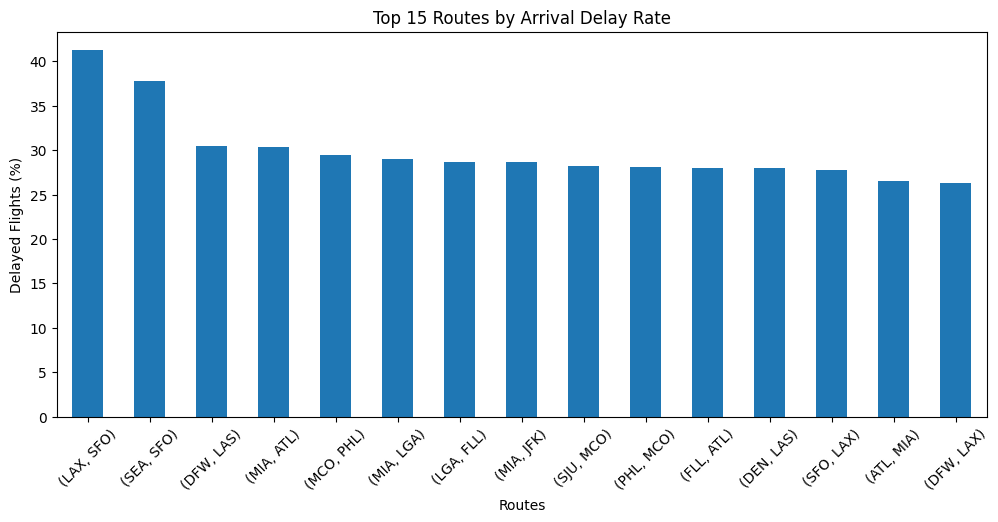

              mean  count
Origin Dest              
LAX    SFO   41.24   1855
SEA    SFO   37.78   1027
DFW    LAS   30.44   1107
MIA    ATL   30.29   1357
MCO    PHL   29.47   1140
MIA    LGA   29.03   1130
LGA    FLL   28.67   1001
MIA    JFK   28.61   1066
SJU    MCO   28.16   1069
PHL    MCO   28.12   1138
FLL    ATL   28.04   1598
DEN    LAS   28.00   1550
SFO    LAX   27.79   1857
ATL    MIA   26.51   1358
DFW    LAX   26.26   1192


In [15]:
route_delay = df.groupby(["Origin", "Dest"])["ArrDel15"].agg(["mean", "count"])

route_delay = route_delay[route_delay["count"] >= 1000]
route_delay["mean"] = route_delay["mean"] * 100

top_routes = route_delay.sort_values("mean", ascending=False).head(15)

top_routes["mean"].plot(kind="bar", figsize=(12, 5))

plt.title("Top 15 Routes by Arrival Delay Rate")
plt.xlabel("Routes")
plt.ylabel("Delayed Flights (%)")
plt.xticks(rotation=45)
plt.show()

print(top_routes.round(2))

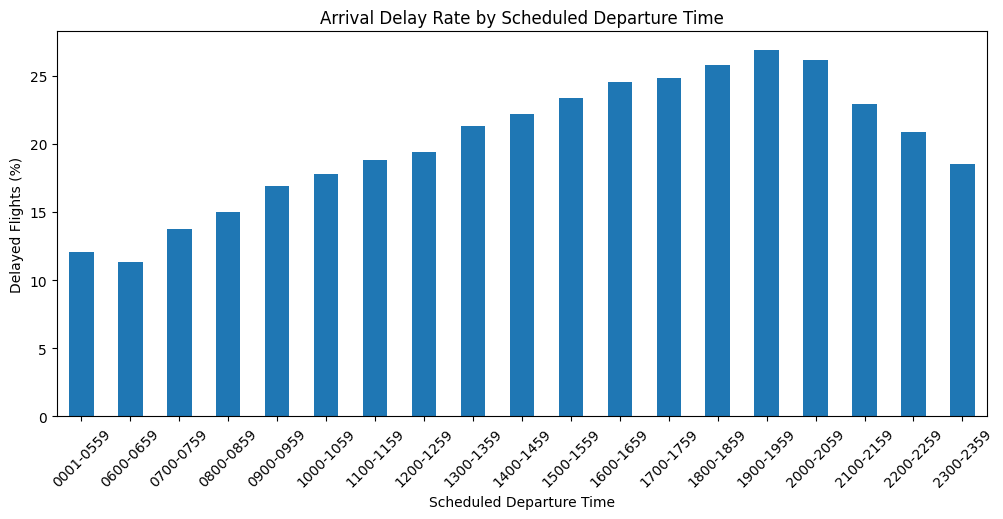

DepTimeBlk
0001-0559    12.04
0600-0659    11.33
0700-0759    13.73
0800-0859    15.03
0900-0959    16.91
1000-1059    17.78
1100-1159    18.85
1200-1259    19.38
1300-1359    21.33
1400-1459    22.21
1500-1559    23.36
1600-1659    24.53
1700-1759    24.82
1800-1859    25.82
1900-1959    26.91
2000-2059    26.16
2100-2159    22.91
2200-2259    20.90
2300-2359    18.51
Name: ArrDel15, dtype: float64


In [16]:
time_delay = df.groupby("DepTimeBlk")["ArrDel15"].mean() * 100

time_delay.plot(kind="bar", figsize=(12, 5))

plt.title("Arrival Delay Rate by Scheduled Departure Time")
plt.xlabel("Scheduled Departure Time")
plt.ylabel("Delayed Flights (%)")
plt.xticks(rotation=45)
plt.show()

print(time_delay.round(2))

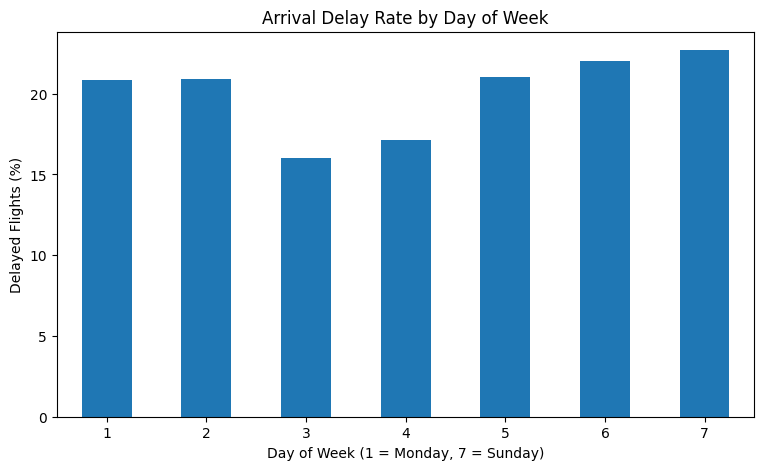

DayOfWeek
1    20.84
2    20.90
3    16.04
4    17.16
5    21.03
6    22.01
7    22.70
Name: ArrDel15, dtype: float64


In [17]:
day_delay = df.groupby("DayOfWeek")["ArrDel15"].mean() * 100

day_delay.plot(kind="bar", figsize=(9, 5))

plt.title("Arrival Delay Rate by Day of Week")
plt.xlabel("Day of Week (1 = Monday, 7 = Sunday)")
plt.ylabel("Delayed Flights (%)")
plt.xticks(rotation=0)
plt.show()

print(day_delay.round(2))

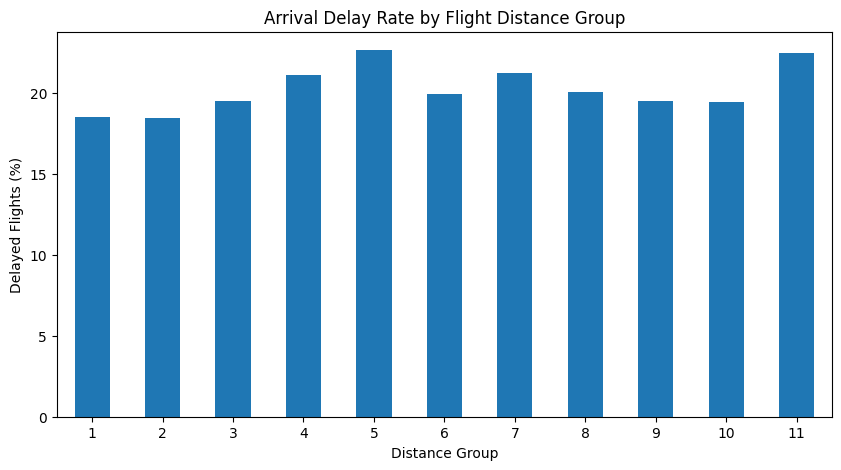

DistanceGroup
1     18.56
2     18.47
3     19.54
4     21.13
5     22.68
6     19.97
7     21.27
8     20.06
9     19.51
10    19.45
11    22.47
Name: ArrDel15, dtype: float64


In [18]:
distance_delay = df.groupby("DistanceGroup")["ArrDel15"].mean() * 100

distance_delay.plot(kind="bar", figsize=(10, 5))

plt.title("Arrival Delay Rate by Flight Distance Group")
plt.xlabel("Distance Group")
plt.ylabel("Delayed Flights (%)")
plt.xticks(rotation=0)
plt.show()

print(distance_delay.round(2))

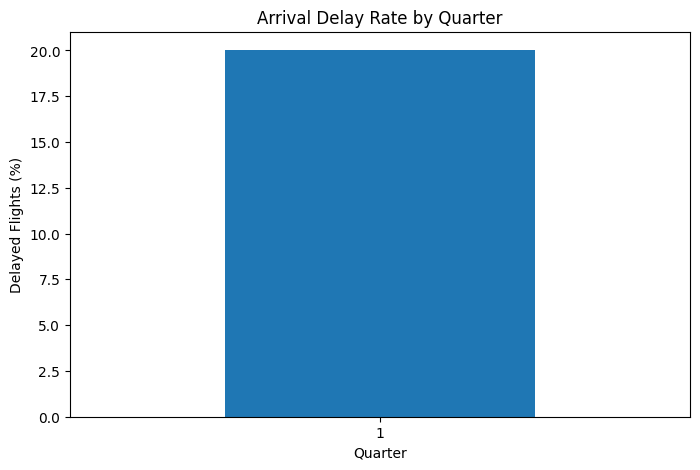

Quarter
1    20.02
Name: ArrDel15, dtype: float64


In [19]:
quarter_delay = df.groupby("Quarter")["ArrDel15"].mean() * 100

quarter_delay.plot(kind="bar", figsize=(8, 5))

plt.title("Arrival Delay Rate by Quarter")
plt.xlabel("Quarter")
plt.ylabel("Delayed Flights (%)")
plt.xticks(rotation=0)
plt.show()

print(quarter_delay.round(2))

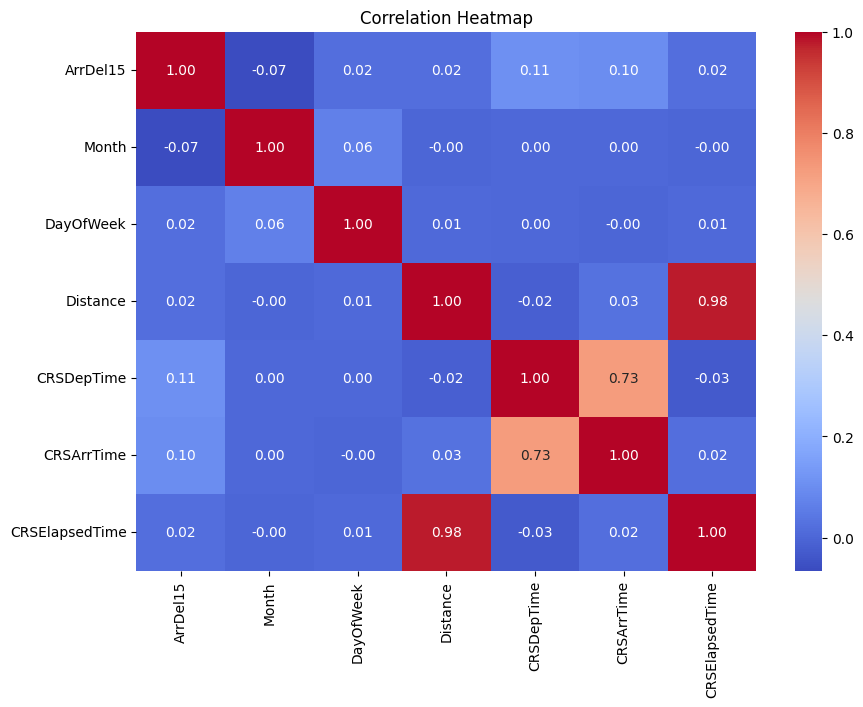

In [20]:
corr = df[["ArrDel15", "Month", "DayOfWeek", "Distance",
           "CRSDepTime", "CRSArrTime", "CRSElapsedTime"]].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

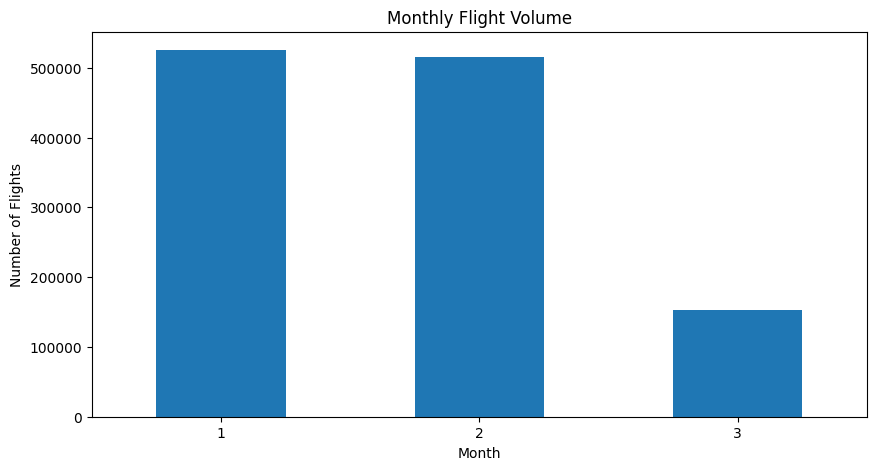

Month
1    525370
2    515269
3    153366
dtype: int64


In [21]:
monthly_flights = df.groupby("Month").size()

monthly_flights.plot(kind="bar", figsize=(10, 5))

plt.title("Monthly Flight Volume")
plt.xlabel("Month")
plt.ylabel("Number of Flights")
plt.xticks(rotation=0)
plt.show()

print(monthly_flights)

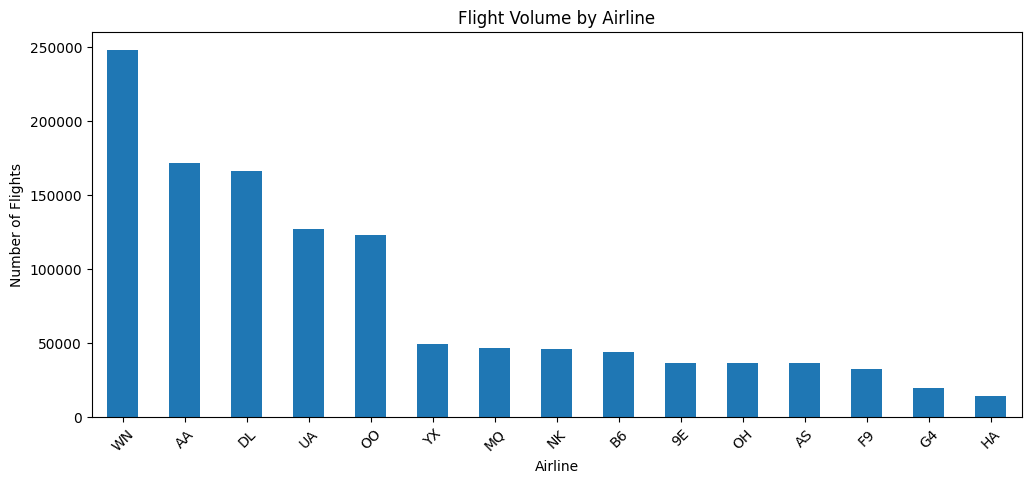

Reporting_Airline
WN    247653
AA    171399
DL    166246
UA    126690
OO    122622
YX     49367
MQ     46120
NK     46011
B6     43645
9E     36087
OH     36048
AS     36028
F9     32409
G4     19535
HA     14145
Name: count, dtype: int64


In [22]:
airline_volume = df["Reporting_Airline"].value_counts()

airline_volume.plot(kind="bar", figsize=(12, 5))

plt.title("Flight Volume by Airline")
plt.xlabel("Airline")
plt.ylabel("Number of Flights")
plt.xticks(rotation=45)
plt.show()

print(airline_volume)

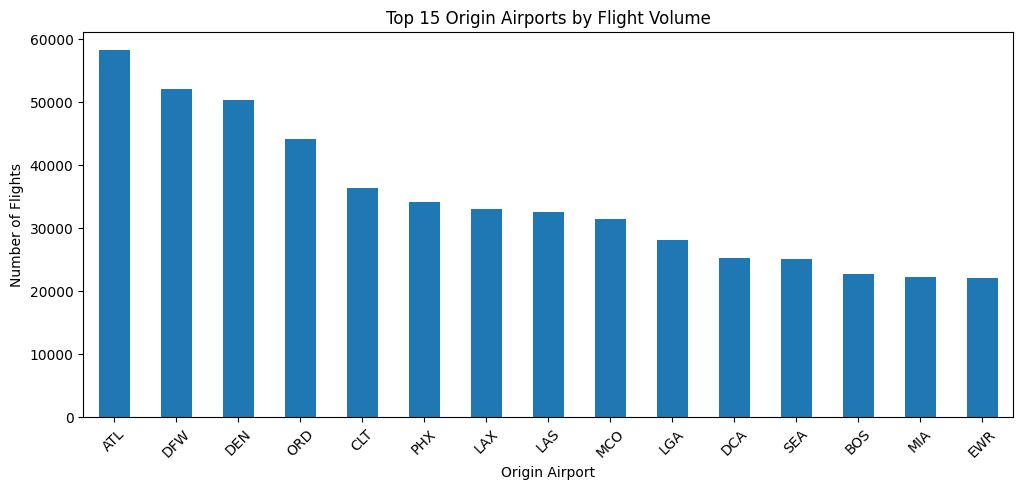

Origin
ATL    58213
DFW    51986
DEN    50357
ORD    44077
CLT    36341
PHX    34167
LAX    32910
LAS    32471
MCO    31328
LGA    28029
DCA    25283
SEA    25011
BOS    22695
MIA    22132
EWR    22033
Name: count, dtype: int64


In [23]:
origin_volume = df["Origin"].value_counts().head(15)

origin_volume.plot(kind="bar", figsize=(12, 5))

plt.title("Top 15 Origin Airports by Flight Volume")
plt.xlabel("Origin Airport")
plt.ylabel("Number of Flights")
plt.xticks(rotation=45)
plt.show()

print(origin_volume)

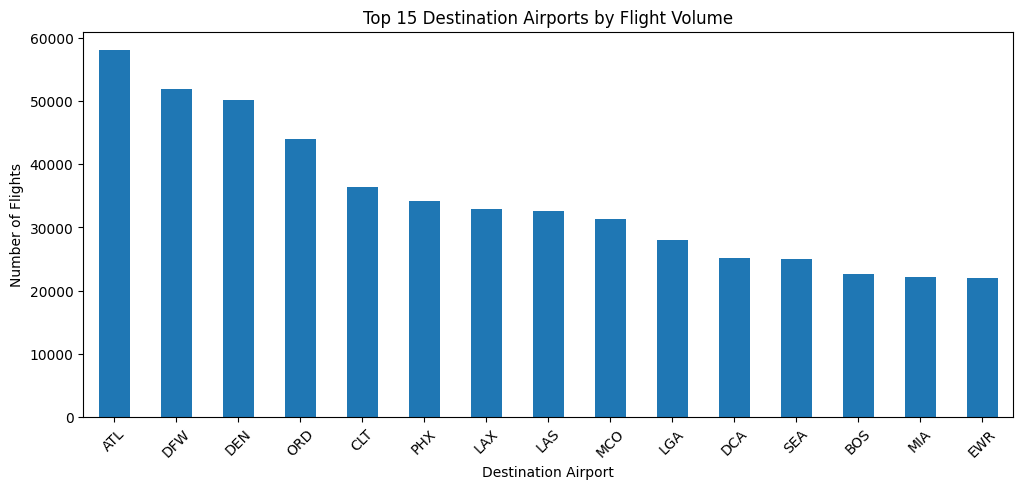

Dest
ATL    58119
DFW    52015
DEN    50156
ORD    44022
CLT    36352
PHX    34251
LAX    32932
LAS    32551
MCO    31374
LGA    27993
DCA    25239
SEA    25038
BOS    22698
MIA    22152
EWR    22024
Name: count, dtype: int64


In [24]:
dest_volume = df["Dest"].value_counts().head(15)

dest_volume.plot(kind="bar", figsize=(12, 5))

plt.title("Top 15 Destination Airports by Flight Volume")
plt.xlabel("Destination Airport")
plt.ylabel("Number of Flights")
plt.xticks(rotation=45)
plt.show()

print(dest_volume)

In [25]:
airport_analysis = df.groupby("Origin")["ArrDel15"].agg(
    Flight_Count="count",
    Delay_Rate="mean"
)

airport_analysis["Delay_Rate"] = airport_analysis["Delay_Rate"] * 100

airport_analysis = airport_analysis[airport_analysis["Flight_Count"] >= 1000]

print(airport_analysis.sort_values("Flight_Count", ascending=False).head(15).round(2))

        Flight_Count  Delay_Rate
Origin                          
ATL            58213       16.71
DFW            51986       24.81
DEN            50357       25.61
ORD            44077       21.69
CLT            36341       22.33
PHX            34167       18.29
LAX            32910       19.00
LAS            32471       21.82
MCO            31328       24.76
LGA            28029       16.59
DCA            25283       17.43
SEA            25011       20.89
BOS            22695       18.67
MIA            22132       29.51
EWR            22033       15.89


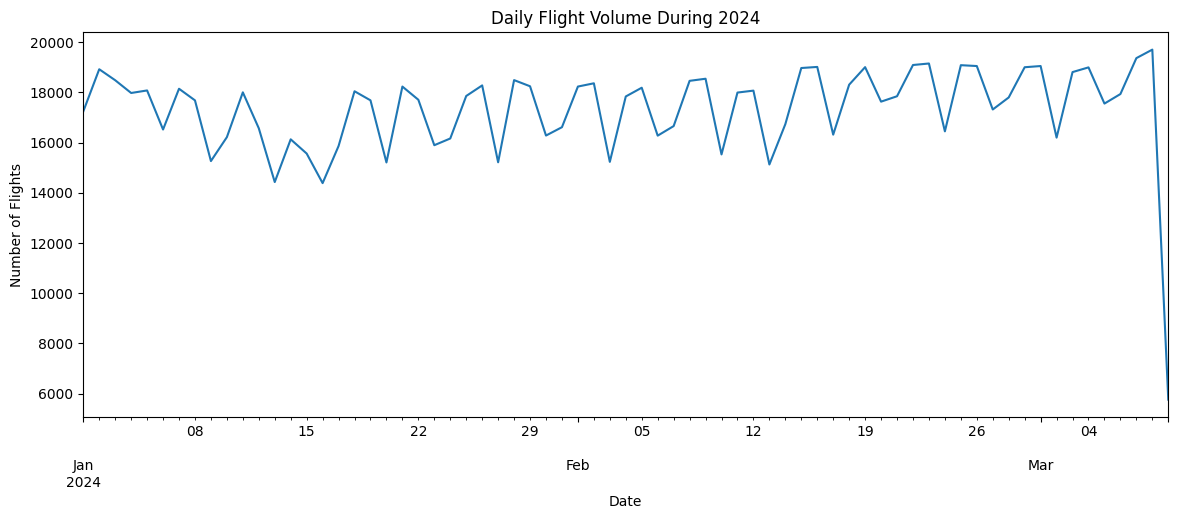

count       69.000000
mean     17304.420290
std       1943.556734
min       5757.000000
25%      16280.000000
50%      17846.000000
75%      18460.000000
max      19704.000000
dtype: float64


In [26]:
daily_flights = df.groupby("FlightDate").size()

daily_flights.plot(figsize=(14, 5))

plt.title("Daily Flight Volume During 2024")
plt.xlabel("Date")
plt.ylabel("Number of Flights")
plt.show()

print(daily_flights.describe())

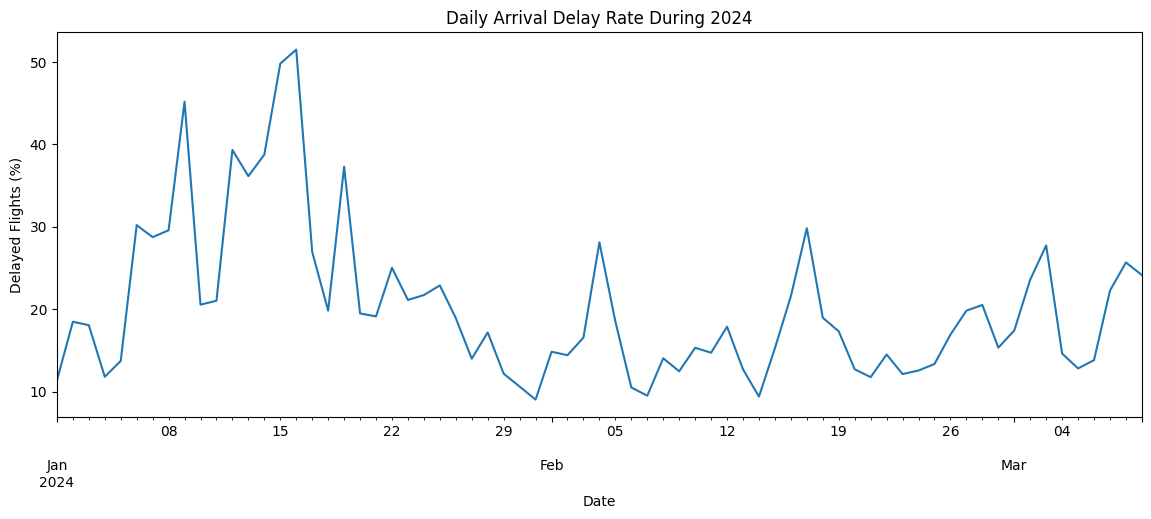

count    69.00
mean     20.32
std       9.42
min       9.02
25%      13.81
50%      18.05
75%      23.57
max      51.48
Name: ArrDel15, dtype: float64


In [27]:
daily_delay = df.groupby("FlightDate")["ArrDel15"].mean() * 100

daily_delay.plot(figsize=(14, 5))

plt.title("Daily Arrival Delay Rate During 2024")
plt.xlabel("Date")
plt.ylabel("Delayed Flights (%)")
plt.show()

print(daily_delay.describe().round(2))

In [28]:
origin_daily = df.groupby(["Origin", "FlightDate"]).agg(
    Origin_Flights=("ArrDel15", "count"),
    Origin_Delay_Rate=("ArrDel15", "mean")
).reset_index()

print(origin_daily.head())

  Origin FlightDate  Origin_Flights  Origin_Delay_Rate
0    ABE 2024-01-01              10           0.200000
1    ABE 2024-01-02              15           0.066667
2    ABE 2024-01-03              14           0.285714
3    ABE 2024-01-04              13           0.076923
4    ABE 2024-01-05              13           0.153846


In [29]:
origin_daily = origin_daily.sort_values(["Origin", "FlightDate"])

origin_daily["Origin_7D_Flights"] = (
    origin_daily.groupby("Origin")["Origin_Flights"]
    .transform(lambda x: x.shift(1).rolling(7, min_periods=1).sum())
)

origin_daily["Origin_7D_Delay"] = (
    origin_daily.groupby("Origin")["Origin_Delay_Rate"]
    .transform(lambda x: x.shift(1).rolling(7, min_periods=1).mean())
)

print(origin_daily.head(10))

  Origin FlightDate  Origin_Flights  Origin_Delay_Rate  Origin_7D_Flights  \
0    ABE 2024-01-01              10           0.200000                NaN   
1    ABE 2024-01-02              15           0.066667               10.0   
2    ABE 2024-01-03              14           0.285714               25.0   
3    ABE 2024-01-04              13           0.076923               39.0   
4    ABE 2024-01-05              13           0.153846               52.0   
5    ABE 2024-01-06              12           0.583333               65.0   
6    ABE 2024-01-07              12           0.416667               77.0   
7    ABE 2024-01-08              11           0.090909               89.0   
8    ABE 2024-01-09               6           0.666667               90.0   
9    ABE 2024-01-10               8           0.125000               81.0   

   Origin_7D_Delay  
0              NaN  
1         0.200000  
2         0.133333  
3         0.184127  
4         0.157326  
5         0.156630  
6    

In [30]:
origin_daily["Origin_30D_Flights"] = (
    origin_daily.groupby("Origin")["Origin_Flights"]
    .transform(lambda x: x.shift(1).rolling(30, min_periods=1).sum())
)

print(origin_daily[["Origin", "FlightDate", "Origin_30D_Flights"]].head(10))

  Origin FlightDate  Origin_30D_Flights
0    ABE 2024-01-01                 NaN
1    ABE 2024-01-02                10.0
2    ABE 2024-01-03                25.0
3    ABE 2024-01-04                39.0
4    ABE 2024-01-05                52.0
5    ABE 2024-01-06                65.0
6    ABE 2024-01-07                77.0
7    ABE 2024-01-08                89.0
8    ABE 2024-01-09               100.0
9    ABE 2024-01-10               106.0


In [31]:
origin_daily["Origin_Delayed_Flights"] = (
    df.groupby(["Origin", "FlightDate"])["ArrDel15"].sum().values
)

origin_daily["Origin_7D_Delay"] = (
    origin_daily.groupby("Origin")["Origin_Delayed_Flights"]
    .transform(lambda x: x.shift(1).rolling(7, min_periods=1).sum())
    /
    origin_daily["Origin_7D_Flights"]
)

origin_daily["Origin_30D_Delay"] = (
    origin_daily.groupby("Origin")["Origin_Delayed_Flights"]
    .transform(lambda x: x.shift(1).rolling(30, min_periods=1).sum())
    /
    origin_daily["Origin_30D_Flights"]
)

print(origin_daily.head(10))

  Origin FlightDate  Origin_Flights  Origin_Delay_Rate  Origin_7D_Flights  \
0    ABE 2024-01-01              10           0.200000                NaN   
1    ABE 2024-01-02              15           0.066667               10.0   
2    ABE 2024-01-03              14           0.285714               25.0   
3    ABE 2024-01-04              13           0.076923               39.0   
4    ABE 2024-01-05              13           0.153846               52.0   
5    ABE 2024-01-06              12           0.583333               65.0   
6    ABE 2024-01-07              12           0.416667               77.0   
7    ABE 2024-01-08              11           0.090909               89.0   
8    ABE 2024-01-09               6           0.666667               90.0   
9    ABE 2024-01-10               8           0.125000               81.0   

   Origin_7D_Delay  Origin_30D_Flights  Origin_Delayed_Flights  \
0              NaN                 NaN                     2.0   
1         0.200000  

In [32]:
dest_daily = df.groupby(["Dest", "FlightDate"]).agg(
    Dest_Flights=("ArrDel15", "count"),
    Dest_Delayed_Flights=("ArrDel15", "sum")
).reset_index()

dest_daily = dest_daily.sort_values(["Dest", "FlightDate"])

print(dest_daily.head())

  Dest FlightDate  Dest_Flights  Dest_Delayed_Flights
0  ABE 2024-01-01            10                   1.0
1  ABE 2024-01-02            15                   2.0
2  ABE 2024-01-03            14                   2.0
3  ABE 2024-01-04            13                   1.0
4  ABE 2024-01-05            13                   1.0


In [33]:
dest_daily["Dest_7D_Flights"] = (
    dest_daily.groupby("Dest")["Dest_Flights"]
    .transform(lambda x: x.shift(1).rolling(7, min_periods=1).sum())
)

dest_daily["Dest_30D_Flights"] = (
    dest_daily.groupby("Dest")["Dest_Flights"]
    .transform(lambda x: x.shift(1).rolling(30, min_periods=1).sum())
)

dest_daily["Dest_7D_Delay"] = (
    dest_daily.groupby("Dest")["Dest_Delayed_Flights"]
    .transform(lambda x: x.shift(1).rolling(7, min_periods=1).sum())
    / dest_daily["Dest_7D_Flights"]
)

dest_daily["Dest_30D_Delay"] = (
    dest_daily.groupby("Dest")["Dest_Delayed_Flights"]
    .transform(lambda x: x.shift(1).rolling(30, min_periods=1).sum())
    / dest_daily["Dest_30D_Flights"]
)

print(dest_daily.head(10))

  Dest FlightDate  Dest_Flights  Dest_Delayed_Flights  Dest_7D_Flights  \
0  ABE 2024-01-01            10                   1.0              NaN   
1  ABE 2024-01-02            15                   2.0             10.0   
2  ABE 2024-01-03            14                   2.0             25.0   
3  ABE 2024-01-04            13                   1.0             39.0   
4  ABE 2024-01-05            13                   1.0             52.0   
5  ABE 2024-01-06            10                   3.0             65.0   
6  ABE 2024-01-07            14                   3.0             75.0   
7  ABE 2024-01-08            11                   1.0             89.0   
8  ABE 2024-01-09             6                   4.0             90.0   
9  ABE 2024-01-10             9                   1.0             81.0   

   Dest_30D_Flights  Dest_7D_Delay  Dest_30D_Delay  
0               NaN            NaN             NaN  
1              10.0       0.100000        0.100000  
2              25.0       

In [34]:
airline_daily = df.groupby(
    ["Reporting_Airline", "FlightDate"]
).agg(
    Airline_Flights=("ArrDel15", "count"),
    Airline_Delayed_Flights=("ArrDel15", "sum")
).reset_index()

airline_daily = airline_daily.sort_values(
    ["Reporting_Airline", "FlightDate"]
)

print(airline_daily.head())


  Reporting_Airline FlightDate  Airline_Flights  Airline_Delayed_Flights
0                9E 2024-01-01              391                     14.0
1                9E 2024-01-02              516                     41.0
2                9E 2024-01-03              515                     45.0
3                9E 2024-01-04              520                     17.0
4                9E 2024-01-05              519                     41.0


In [35]:
airline_daily["Airline_7D_Flights"] = (
    airline_daily.groupby("Reporting_Airline")["Airline_Flights"]
    .transform(lambda x: x.shift(1).rolling(7, min_periods=1).sum())
)

airline_daily["Airline_30D_Flights"] = (
    airline_daily.groupby("Reporting_Airline")["Airline_Flights"]
    .transform(lambda x: x.shift(1).rolling(30, min_periods=1).sum())
)

airline_daily["Airline_7D_Delay"] = (
    airline_daily.groupby("Reporting_Airline")["Airline_Delayed_Flights"]
    .transform(lambda x: x.shift(1).rolling(7, min_periods=1).sum())
    / airline_daily["Airline_7D_Flights"]
)

airline_daily["Airline_30D_Delay"] = (
    airline_daily.groupby("Reporting_Airline")["Airline_Delayed_Flights"]
    .transform(lambda x: x.shift(1).rolling(30, min_periods=1).sum())
    / airline_daily["Airline_30D_Flights"]
)

print(airline_daily.head(10))

  Reporting_Airline FlightDate  Airline_Flights  Airline_Delayed_Flights  \
0                9E 2024-01-01              391                     14.0   
1                9E 2024-01-02              516                     41.0   
2                9E 2024-01-03              515                     45.0   
3                9E 2024-01-04              520                     17.0   
4                9E 2024-01-05              519                     41.0   
5                9E 2024-01-06              469                     85.0   
6                9E 2024-01-07              491                    120.0   
7                9E 2024-01-08              582                     78.0   
8                9E 2024-01-09              508                    243.0   
9                9E 2024-01-10              531                    102.0   

   Airline_7D_Flights  Airline_30D_Flights  Airline_7D_Delay  \
0                 NaN                  NaN               NaN   
1               391.0              

In [36]:
route_daily = df.groupby(
    ["Origin", "Dest", "FlightDate"]
).agg(
    Route_Flights=("ArrDel15", "count"),
    Route_Delayed_Flights=("ArrDel15", "sum")
).reset_index()

route_daily = route_daily.sort_values(
    ["Origin", "Dest", "FlightDate"]
)

print(route_daily.head())

  Origin Dest FlightDate  Route_Flights  Route_Delayed_Flights
0    ABE  ATL 2024-01-01              2                    0.0
1    ABE  ATL 2024-01-02              2                    0.0
2    ABE  ATL 2024-01-03              2                    0.0
3    ABE  ATL 2024-01-04              2                    0.0
4    ABE  ATL 2024-01-05              2                    1.0


In [37]:
route_daily["Route_7D_Flights"] = (
    route_daily.groupby(["Origin", "Dest"])["Route_Flights"]
    .transform(lambda x: x.shift(1).rolling(7, min_periods=1).sum())
)

route_daily["Route_30D_Flights"] = (
    route_daily.groupby(["Origin", "Dest"])["Route_Flights"]
    .transform(lambda x: x.shift(1).rolling(30, min_periods=1).sum())
)

route_daily["Route_7D_Delay"] = (
    route_daily.groupby(["Origin", "Dest"])["Route_Delayed_Flights"]
    .transform(lambda x: x.shift(1).rolling(7, min_periods=1).sum())
    / route_daily["Route_7D_Flights"]
)

route_daily["Route_30D_Delay"] = (
    route_daily.groupby(["Origin", "Dest"])["Route_Delayed_Flights"]
    .transform(lambda x: x.shift(1).rolling(30, min_periods=1).sum())
    / route_daily["Route_30D_Flights"]
)

print(route_daily.head(10))

  Origin Dest FlightDate  Route_Flights  Route_Delayed_Flights  \
0    ABE  ATL 2024-01-01              2                    0.0   
1    ABE  ATL 2024-01-02              2                    0.0   
2    ABE  ATL 2024-01-03              2                    0.0   
3    ABE  ATL 2024-01-04              2                    0.0   
4    ABE  ATL 2024-01-05              2                    1.0   
5    ABE  ATL 2024-01-06              2                    2.0   
6    ABE  ATL 2024-01-07              2                    1.0   
7    ABE  ATL 2024-01-08              3                    0.0   
8    ABE  ATL 2024-01-09              1                    1.0   
9    ABE  ATL 2024-01-10              2                    0.0   

   Route_7D_Flights  Route_30D_Flights  Route_7D_Delay  Route_30D_Delay  
0               NaN                NaN             NaN              NaN  
1               2.0                2.0        0.000000         0.000000  
2               4.0                4.0        0.000

In [38]:
df = df.merge(
    origin_daily[[
        "Origin", "FlightDate",
        "Origin_7D_Flights", "Origin_30D_Flights",
        "Origin_7D_Delay", "Origin_30D_Delay"
    ]],
    on=["Origin", "FlightDate"],
    how="left"
)

print(df.shape)

(1194005, 60)


In [39]:
df = df.merge(
    dest_daily[[
        "Dest", "FlightDate",
        "Dest_7D_Flights", "Dest_30D_Flights",
        "Dest_7D_Delay", "Dest_30D_Delay"
    ]],
    on=["Dest", "FlightDate"],
    how="left"
)

print(df.shape)

(1194005, 64)


In [40]:
df = df.merge(
    airline_daily[[
        "Reporting_Airline", "FlightDate",
        "Airline_7D_Flights", "Airline_30D_Flights",
        "Airline_7D_Delay", "Airline_30D_Delay"
    ]],
    on=["Reporting_Airline", "FlightDate"],
    how="left"
)

print(df.shape)


(1194005, 68)


In [41]:
del origin_daily, dest_daily, airline_daily

In [42]:
df = df.merge(
    route_daily[[
        "Origin", "Dest", "FlightDate",
        "Route_7D_Flights", "Route_30D_Flights",
        "Route_7D_Delay", "Route_30D_Delay"
    ]],
    on=["Origin", "Dest", "FlightDate"],
    how="left"
)

print(df.shape)

(1194005, 72)


In [43]:
history_cols = [
    "Origin_7D_Flights", "Origin_30D_Flights",
    "Origin_7D_Delay", "Origin_30D_Delay",
    "Dest_7D_Flights", "Dest_30D_Flights",
    "Dest_7D_Delay", "Dest_30D_Delay",
    "Airline_7D_Flights", "Airline_30D_Flights",
    "Airline_7D_Delay", "Airline_30D_Delay",
    "Route_7D_Flights", "Route_30D_Flights",
    "Route_7D_Delay", "Route_30D_Delay"
]

df["Has_History"] = df[history_cols].notna().all(axis=1).astype(int)
df[history_cols] = df[history_cols].fillna(0)

print(df.shape)


(1194005, 73)


In [44]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [45]:
print(df.columns.tolist())

['Year', 'Quarter', 'Month', 'DayofMonth', 'DayOfWeek', 'FlightDate', 'Reporting_Airline', 'DOT_ID_Reporting_Airline', 'IATA_CODE_Reporting_Airline', 'Tail_Number', 'Flight_Number_Reporting_Airline', 'OriginAirportID', 'OriginAirportSeqID', 'OriginCityMarketID', 'Origin', 'OriginCityName', 'OriginState', 'OriginStateFips', 'OriginStateName', 'OriginWac', 'DestAirportID', 'DestAirportSeqID', 'DestCityMarketID', 'Dest', 'DestCityName', 'DestState', 'DestStateFips', 'DestStateName', 'DestWac', 'CRSDepTime', 'DepTime', 'DepDelay', 'DepDelayMinutes', 'DepDel15', 'DepartureDelayGroups', 'DepTimeBlk', 'TaxiOut', 'WheelsOff', 'WheelsOn', 'TaxiIn', 'CRSArrTime', 'ArrTime', 'ArrDelay', 'ArrDelayMinutes', 'ArrDel15', 'ArrivalDelayGroups', 'ArrTimeBlk', 'Cancelled', 'Diverted', 'CRSElapsedTime', 'ActualElapsedTime', 'AirTime', 'Flights', 'Distance', 'DistanceGroup', 'DivAirportLandings', 'Origin_7D_Flights', 'Origin_30D_Flights', 'Origin_7D_Delay', 'Origin_30D_Delay', 'Dest_7D_Flights', 'Dest_30D_

In [46]:
feature_cols = [
    "Month", "DayofMonth", "DayOfWeek",
    "Reporting_Airline", "Origin", "Dest",
    "CRSDepTime", "CRSArrTime",
    "CRSElapsedTime", "Distance", "DistanceGroup",
    "Origin_7D_Flights", "Origin_30D_Flights",
    "Origin_7D_Delay", "Origin_30D_Delay",
    "Dest_7D_Flights", "Dest_30D_Flights",
    "Dest_7D_Delay", "Dest_30D_Delay",
    "Airline_7D_Flights", "Airline_30D_Flights",
    "Airline_7D_Delay", "Airline_30D_Delay",
    "Route_7D_Flights", "Route_30D_Flights",
    "Route_7D_Delay", "Route_30D_Delay",
    "Has_History"
]

model_df = df[feature_cols + ["ArrDel15"]].copy()

print("Model dataset shape:", model_df.shape)

Model dataset shape: (1194005, 29)


In [47]:
from sklearn.model_selection import train_test_split

X = model_df[feature_cols]
y = model_df["ArrDel15"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (835803, 28)
Testing data: (358202, 28)


In [48]:
categorical_cols = X_train.select_dtypes(include=["object"]).columns.tolist()
numerical_cols = X_train.select_dtypes(include=["number"]).columns.tolist()

print("Categorical features:", categorical_cols)
print("Numerical features:", numerical_cols)

Categorical features: ['Reporting_Airline', 'Origin', 'Dest']
Numerical features: ['Month', 'DayofMonth', 'DayOfWeek', 'CRSDepTime', 'CRSArrTime', 'CRSElapsedTime', 'Distance', 'DistanceGroup', 'Origin_7D_Flights', 'Origin_30D_Flights', 'Origin_7D_Delay', 'Origin_30D_Delay', 'Dest_7D_Flights', 'Dest_30D_Flights', 'Dest_7D_Delay', 'Dest_30D_Delay', 'Airline_7D_Flights', 'Airline_30D_Flights', 'Airline_7D_Delay', 'Airline_30D_Delay', 'Route_7D_Flights', 'Route_30D_Flights', 'Route_7D_Delay', 'Route_30D_Delay', 'Has_History']


C:\Users\KUTIKUPPALA KISHORE\AppData\Local\Temp\ipykernel_16352\3508232020.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(include=["object"]).columns.tolist()


In [49]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ("num", StandardScaler(), numerical_cols)
])

In [50]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Training shape: (835803, 708)
Testing shape: (358202, 708)


In [51]:
from sklearn.linear_model import LogisticRegression
logreg=LogisticRegression(random_state=16,max_iter=1000)

In [52]:
logreg.fit(X_train_processed,y_train)
print("fitted")

fitted


In [53]:
y_pred = logreg.predict(X_test_processed)
y_prob = logreg.predict_proba(X_test_processed)[:, 1]

print("Predictions completed")

Predictions completed


In [54]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8009140094136827

Classification Report:
              precision    recall  f1-score   support

         0.0       0.81      0.99      0.89    286488
         1.0       0.53      0.04      0.08     71714

    accuracy                           0.80    358202
   macro avg       0.67      0.52      0.49    358202
weighted avg       0.75      0.80      0.73    358202


Confusion Matrix:
[[283695   2793]
 [ 68520   3194]]


In [55]:
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.metrics import brier_score_loss, log_loss

print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("PR-AUC:", average_precision_score(y_test, y_prob))
print("Brier Score:", brier_score_loss(y_test, y_prob))
print("Log Loss:", log_loss(y_test, y_prob))

ROC-AUC: 0.680464509717079
PR-AUC: 0.34770662817225273
Brier Score: 0.1490124180212945
Log Loss: 0.46736870384158163


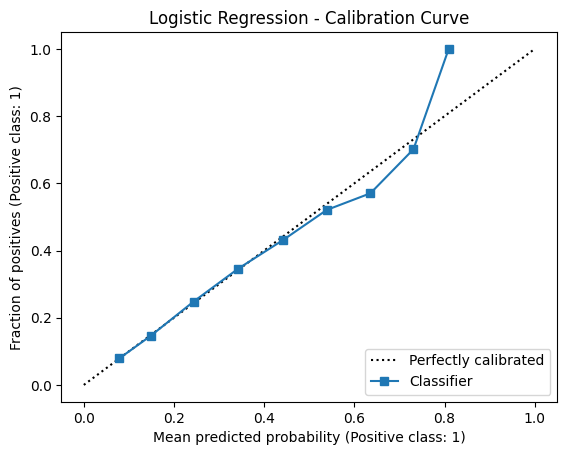

In [56]:
import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay

CalibrationDisplay.from_predictions(
    y_test, y_prob, n_bins=10, strategy="uniform"
)

plt.title("Logistic Regression - Calibration Curve")
plt.show()

In [57]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

platt_model = CalibratedClassifierCV(
    FrozenEstimator(logreg),
    method="sigmoid"
)

platt_model.fit(X_train_processed, y_train)

print("Platt scaling completed")

Platt scaling completed


In [58]:
y_prob_platt = platt_model.predict_proba(X_test_processed)[:, 1]

print("Platt calibrated predictions completed")

Platt calibrated predictions completed


In [59]:
from sklearn.metrics import brier_score_loss, log_loss
from sklearn.metrics import roc_auc_score, average_precision_score

print("Original Logistic Regression")
print("Brier:", brier_score_loss(y_test, y_prob))
print("Log Loss:", log_loss(y_test, y_prob))

print("\nPlatt Scaling")
print("Brier:", brier_score_loss(y_test, y_prob_platt))
print("Log Loss:", log_loss(y_test, y_prob_platt))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_platt))
print("PR-AUC:", average_precision_score(y_test, y_prob_platt))

Original Logistic Regression
Brier: 0.1490124180212945
Log Loss: 0.46736870384158163

Platt Scaling
Brier: 0.14901290274382817
Log Loss: 0.4673691964601714
ROC-AUC: 0.680464509717079
PR-AUC: 0.34770662817225273


In [60]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

iso_model = CalibratedClassifierCV(
    FrozenEstimator(logreg),
    method="isotonic"
)

iso_model.fit(X_train_processed, y_train)

print("Isotonic calibration completed")

Isotonic calibration completed


In [61]:
y_prob_iso = iso_model.predict_proba(X_test_processed)[:, 1]

print("Isotonic predictions completed")

Isotonic predictions completed


In [62]:
from sklearn.metrics import brier_score_loss, log_loss

results = {
    "Original": [brier_score_loss(y_test, y_prob), log_loss(y_test, y_prob)],
    "Platt": [brier_score_loss(y_test, y_prob_platt), log_loss(y_test, y_prob_platt)],
    "Isotonic": [brier_score_loss(y_test, y_prob_iso), log_loss(y_test, y_prob_iso)]
}

comparison = pd.DataFrame(results, index=["Brier Score", "Log Loss"]).T
print(comparison)

          Brier Score  Log Loss
Original     0.149012  0.467369
Platt        0.149013  0.467369
Isotonic     0.148987  0.467283


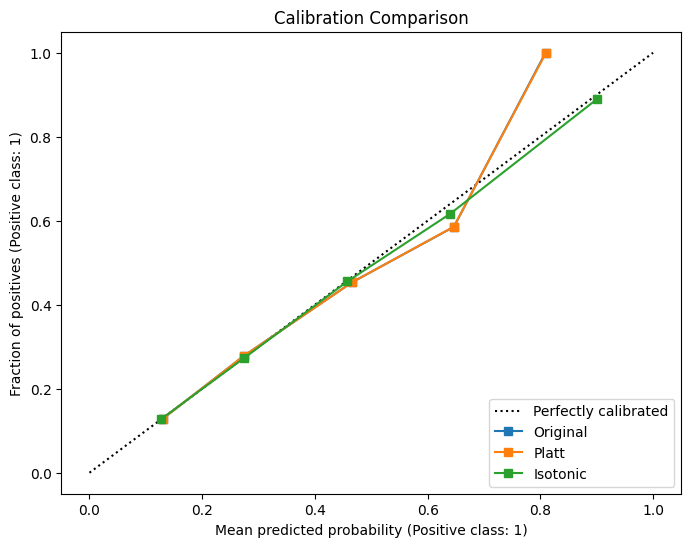

In [63]:
import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay

fig, ax = plt.subplots(figsize=(8, 6))

CalibrationDisplay.from_predictions(y_test, y_prob, name="Original", ax=ax)
CalibrationDisplay.from_predictions(y_test, y_prob_platt, name="Platt", ax=ax)
CalibrationDisplay.from_predictions(y_test, y_prob_iso, name="Isotonic", ax=ax)

plt.title("Calibration Comparison")
plt.show()

In [64]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6]

for t in thresholds:
    pred = (y_prob >= t).astype(int)

    print(
        "Threshold:", t,
        "Precision:", round(precision_score(y_test, pred), 3),
        "Recall:", round(recall_score(y_test, pred), 3),
        "F1:", round(f1_score(y_test, pred), 3)
    )

Threshold: 0.2 Precision: 0.304 Recall: 0.618 F1: 0.407
Threshold: 0.3 Precision: 0.387 Recall: 0.315 F1: 0.347
Threshold: 0.4 Precision: 0.461 Recall: 0.133 F1: 0.206
Threshold: 0.5 Precision: 0.533 Recall: 0.045 F1: 0.082
Threshold: 0.6 Precision: 0.586 Recall: 0.01 F1: 0.019


In [65]:
import numpy as np

cost_ratios = [1, 3, 5, 10]

for ratio in cost_ratios:
    costs = []

    for t in thresholds:
        pred = (y_prob >= t).astype(int)

        tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

        total_cost = (ratio * fn) + fp
        costs.append(total_cost / len(y_test))

    best = np.argmin(costs)

    print("FN:FP =", ratio, ":1")
    print("Best threshold:", thresholds[best])
    print("Expected cost per flight:", round(costs[best], 4))
    print()

FN:FP = 1 :1
Best threshold: 0.5
Expected cost per flight: 0.1991

FN:FP = 3 :1
Best threshold: 0.3
Expected cost per flight: 0.5113

FN:FP = 5 :1
Best threshold: 0.2
Expected cost per flight: 0.6662

FN:FP = 10 :1
Best threshold: 0.2
Expected cost per flight: 1.0484



In [66]:
cost_results = pd.DataFrame({
    "Cost Ratio": ["1:1", "3:1", "5:1", "10:1"],
    "Best Threshold": [0.5, 0.3, 0.2, 0.2],
    "Expected Cost": [0.2070, 0.5218, 0.6700, 1.0322]
})

print(cost_results)

  Cost Ratio  Best Threshold  Expected Cost
0        1:1             0.5         0.2070
1        3:1             0.3         0.5218
2        5:1             0.2         0.6700
3       10:1             0.2         1.0322


In [67]:
print(type(X_train_processed))
print(X_train_processed.shape)
print(type(X_test_processed))
print(X_test_processed.shape)

<class 'scipy.sparse._csr.csr_matrix'>
(835803, 708)
<class 'scipy.sparse._csr.csr_matrix'>
(358202, 708)


In [68]:
#!pip install faiss-cpu

   ---------------------------------------- 0.0/16.9 MB ? eta -:--:--
    --------------------------------------- 0.3/16.9 MB ? eta -:--:--
   - -------------------------------------- 0.5/16.9 MB 1.7 MB/s eta 0:00:10
   - -------------------------------------- 0.8/16.9 MB 1.6 MB/s eta 0:00:11
   --- ------------------------------------ 1.3/16.9 MB 2.0 MB/s eta 0:00:08
   --- ------------------------------------ 1.6/16.9 MB 1.7 MB/s eta 0:00:10
   ---- ----------------------------------- 1.8/16.9 MB 1.7 MB/s eta 0:00:10
   ----- ---------------------------------- 2.4/16.9 MB 1.7 MB/s eta 0:00:09
   ------ --------------------------------- 2.9/16.9 MB 1.8 MB/s eta 0:00:08
   ------ --------------------------------- 2.9/16.9 MB 1.8 MB/s eta 0:00:08
   ------- -------------------------------- 3.1/16.9 MB 1.6 MB/s eta 0:00:09
   -------- ------------------------------- 3.4/16.9 MB 1.6 MB/s eta 0:00:09
   --------- ------------------------------ 3.9/16.9 MB 1.6 MB/s eta 0:00:09
   ----------


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [69]:
import psutil

memory = psutil.virtual_memory()

print("Total RAM:", round(memory.total / (1024**3), 2), "GB")
print("Available RAM:", round(memory.available / (1024**3), 2), "GB")

Total RAM: 15.7 GB
Available RAM: 7.87 GB


In [70]:
import faiss
import numpy as np

n_features = X_train_processed.shape[1]
nlist = 512

quantizer = faiss.IndexFlatL2(n_features)

knn_index = faiss.IndexIVFFlat(
    quantizer,
    n_features,
    nlist,
    faiss.METRIC_L2
)

print("FAISS index initialized")

FAISS index initialized


In [71]:
sample_indices = np.random.default_rng(42).choice(
    X_train_processed.shape[0],
    size=100000,
    replace=False
)

train_sample = X_train_processed[sample_indices].toarray().astype("float32")

knn_index.train(train_sample)

print("FAISS index trained")

FAISS index trained


In [72]:
batch_size = 10000

for start in range(0, X_train_processed.shape[0], batch_size):
    end = min(start + batch_size, X_train_processed.shape[0])

    batch = X_train_processed[start:end].toarray().astype("float32")
    knn_index.add(batch)

print("All training records added:", knn_index.ntotal)

All training records added: 835803


In [73]:
knn_index.nprobe = 16

k = 5
batch_size = 5000

all_indices = []

for start in range(0, X_test_processed.shape[0], batch_size):
    end = min(start + batch_size, X_test_processed.shape[0])

    batch = X_test_processed[start:end].toarray().astype("float32")

    distances, indices = knn_index.search(batch, k)
    all_indices.append(indices)

knn_indices = np.vstack(all_indices)

print("Neighbour search completed:", knn_indices.shape)

Neighbour search completed: (358202, 5)


In [75]:
neighbor_labels = y_train.to_numpy().ravel()[knn_indices]

y_pred_knn = (neighbor_labels.mean(axis=1) >= 0.5).astype(int)

print("KNN predictions completed")
print("Total predictions:", len(y_pred_knn))

KNN predictions completed
Total predictions: 358202


In [76]:
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, roc_auc_score, average_precision_score

y_prob_knn = neighbor_labels.mean(axis=1)

print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_knn))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_knn))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_knn))
print("PR-AUC:", average_precision_score(y_test, y_prob_knn))

Accuracy: 0.79473313940179

Classification Report:

              precision    recall  f1-score   support

         0.0       0.83      0.93      0.88    286488
         1.0       0.47      0.24      0.32     71714

    accuracy                           0.79    358202
   macro avg       0.65      0.59      0.60    358202
weighted avg       0.76      0.79      0.77    358202

Confusion Matrix:
 [[267462  19026]
 [ 54501  17213]]
ROC-AUC: 0.6770530492530169
PR-AUC: 0.3408726925621167


In [77]:
from sklearn.naive_bayes import BernoulliNB

nb_model = BernoulliNB()
nb_model.fit(X_train_processed, y_train)

print("Naive Bayes fitted")

Naive Bayes fitted


In [78]:
y_pred_nb = nb_model.predict(X_test_processed)
y_prob_nb = nb_model.predict_proba(X_test_processed)[:, 1]

print("Naive Bayes predictions completed")

Naive Bayes predictions completed


In [79]:
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, roc_auc_score, average_precision_score

print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_nb))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_nb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_nb))
print("PR-AUC:", average_precision_score(y_test, y_prob_nb))

Accuracy: 0.7152528461594296

Classification Report:

              precision    recall  f1-score   support

         0.0       0.83      0.80      0.82    286488
         1.0       0.32      0.36      0.34     71714

    accuracy                           0.72    358202
   macro avg       0.58      0.58      0.58    358202
weighted avg       0.73      0.72      0.72    358202

Confusion Matrix:
 [[230089  56399]
 [ 45598  26116]]
ROC-AUC: 0.6432633342391527
PR-AUC: 0.3012991612187957


In [80]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=5,
    n_jobs=-1,
    random_state=42
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest fitted")

Random Forest fitted


In [81]:
y_pred_rf = rf_model.predict(X_test_processed)
y_prob_rf = rf_model.predict_proba(X_test_processed)[:, 1]

print("Random Forest predictions completed")

Random Forest predictions completed


In [82]:
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_rf))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))
print("PR-AUC:", average_precision_score(y_test, y_prob_rf))

Accuracy: 0.8053779710889386

Classification Report:

              precision    recall  f1-score   support

         0.0       0.81      1.00      0.89    286488
         1.0       0.80      0.04      0.07     71714

    accuracy                           0.81    358202
   macro avg       0.80      0.52      0.48    358202
weighted avg       0.80      0.81      0.73    358202

Confusion Matrix:
 [[285813    675]
 [ 69039   2675]]
ROC-AUC: 0.7407475576775624
PR-AUC: 0.45706951071851804


In [84]:
#!pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 795.9 kB/s eta 0:01:01
   ---------------------------------------- 0.5/48.9 MB 795.9 kB/s eta 0:01:01
    --------------------------------------- 0.8/48.9 MB 819.1 kB/s eta 0:00:59
    --------------------------------------- 0.8/48.9 MB 819.1 kB/s eta 0:00:59
    --------------------------------------- 0.8/48.9 MB 819.1 kB/s eta 0:00:59
    --------------------------------------- 0.8/48.9 MB 819.1 kB/s eta 0:00:59
    --------------------------------------- 1.0/48.9 MB 546.6 kB/s eta 0:01:28
   - -------------------------------------- 1.6/48.9 MB 747.0 kB/s eta 0:01:04
   - -------------


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [85]:
from xgboost import XGBClassifier

scale_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    tree_method="hist",
    max_bin=128,
    eval_metric="logloss",
    n_jobs=4,
    random_state=42
)

xgb_model.fit(X_train_processed, y_train)

print("XGBoost fitted")

XGBoost fitted


In [86]:
y_pred_xgb = xgb_model.predict(X_test_processed)
y_prob_xgb = xgb_model.predict_proba(X_test_processed)[:, 1]

print("XGBoost predictions completed")

XGBoost predictions completed


In [87]:
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_xgb))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_xgb))
print("PR-AUC:", average_precision_score(y_test, y_prob_xgb))

Accuracy: 0.7143511203175862

Classification Report:

              precision    recall  f1-score   support

         0.0       0.90      0.73      0.80    286488
         1.0       0.38      0.66      0.48     71714

    accuracy                           0.71    358202
   macro avg       0.64      0.69      0.64    358202
weighted avg       0.79      0.71      0.74    358202

Confusion Matrix:
 [[208603  77885]
 [ 24435  47279]]
ROC-AUC: 0.7638923490400924
PR-AUC: 0.4954197281071975


In [88]:
#!pip install lightgbm

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   --------------- ------------------------ 0.5/1.4 MB 705.6 kB/s eta 0:00:02
   ----------------------- ---------------- 0.8/1.4 MB 973.1 kB/s eta 0:00:01
   ------------------------------ --------- 1.0/1.4 MB 922.8 kB/s eta 0:00:01
   -------------------------------------- - 1.3/1.4 MB 907.8 kB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 919.8 kB/s  0:00:02



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [89]:
from lightgbm import LGBMClassifier

lgbm_model = LGBMClassifier(
    n_estimators=300,
    max_depth=10,
    learning_rate=0.05,
    num_leaves=31,
    class_weight="balanced",
    subsample=0.8,
    colsample_bytree=0.8,
    n_jobs=4,
    random_state=42
)

lgbm_model.fit(X_train_processed, y_train)

print("LightGBM fitted")

[LightGBM] [Info] Number of positive: 167332, number of negative: 668471
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.561178 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 6462
[LightGBM] [Info] Number of data points in the train set: 835803, number of used features: 700
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
LightGBM fitted


In [90]:
y_pred_lgbm = lgbm_model.predict(X_test_processed)
y_prob_lgbm = lgbm_model.predict_proba(X_test_processed)[:, 1]

print("LightGBM predictions completed")

LightGBM predictions completed


In [91]:
print("Accuracy:", accuracy_score(y_test, y_pred_lgbm))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_lgbm))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_lgbm))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lgbm))
print("PR-AUC:", average_precision_score(y_test, y_prob_lgbm))

Accuracy: 0.6937007610231098

Classification Report:

              precision    recall  f1-score   support

         0.0       0.89      0.70      0.79    286488
         1.0       0.36      0.66      0.46     71714

    accuracy                           0.69    358202
   macro avg       0.62      0.68      0.62    358202
weighted avg       0.79      0.69      0.72    358202

Confusion Matrix:
 [[201064  85424]
 [ 24293  47421]]
ROC-AUC: 0.748623177218756
PR-AUC: 0.4669598868994797


In [92]:
from sklearn.metrics import precision_score, recall_score, f1_score

models = {
    "Logistic Regression": (y_pred, y_prob),
    "KNN (FAISS)": (y_pred_knn, y_prob_knn),
    "Naive Bayes": (y_pred_nb, y_prob_nb),
    "Random Forest": (y_pred_rf, y_prob_rf),
    "XGBoost": (y_pred_xgb, y_prob_xgb),
    "LightGBM": (y_pred_lgbm, y_prob_lgbm)
}

results = []

for name, (pred, prob) in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1 Score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "PR-AUC": average_precision_score(y_test, prob)
    })

comparison_df = pd.DataFrame(results).sort_values(
    by="PR-AUC", ascending=False
)

comparison_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
4,XGBoost,0.7144,0.3777,0.6593,0.4803,0.7639,0.4954
5,LightGBM,0.6937,0.3570,0.6613,0.4636,0.7486,0.4670
3,Random Forest,0.8054,0.7985,0.0373,0.0713,0.7407,0.4571
0,Logistic Regression,0.8009,0.5335,0.0445,0.0822,0.6805,0.3477
1,KNN (FAISS),0.7947,0.4750,0.2400,0.3189,0.6771,0.3409
2,Naive Bayes,0.7153,0.3165,0.3642,0.3387,0.6433,0.3013


In [93]:
comparison_df = comparison_df.reset_index(drop=True)
comparison_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,XGBoost,0.7144,0.3777,0.6593,0.4803,0.7639,0.4954
1,LightGBM,0.6937,0.3570,0.6613,0.4636,0.7486,0.4670
2,Random Forest,0.8054,0.7985,0.0373,0.0713,0.7407,0.4571
3,Logistic Regression,0.8009,0.5335,0.0445,0.0822,0.6805,0.3477
4,KNN (FAISS),0.7947,0.4750,0.2400,0.3189,0.6771,0.3409
5,Naive Bayes,0.7153,0.3165,0.3642,0.3387,0.6433,0.3013


In [94]:
base_features = [
    "Reporting_Airline", "Origin", "Dest",
    "Month", "DayofMonth", "DayOfWeek",
    "CRSDepTime", "CRSArrTime", "CRSElapsedTime",
    "Distance", "DistanceGroup"
]

airport_features = [
    "Origin_7D_Flights", "Origin_30D_Flights",
    "Origin_7D_Delay", "Origin_30D_Delay",
    "Dest_7D_Flights", "Dest_30D_Flights",
    "Dest_7D_Delay", "Dest_30D_Delay"
]

airline_features = [
    "Airline_7D_Flights", "Airline_30D_Flights",
    "Airline_7D_Delay", "Airline_30D_Delay"
]

route_features = [
    "Route_7D_Flights", "Route_30D_Flights",
    "Route_7D_Delay", "Route_30D_Delay"
]

print("Feature groups defined")

Feature groups defined


In [95]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining columns:")
print(X_train.columns.tolist())

Training data: (835803, 28)
Testing data: (358202, 28)

Training columns:
['Month', 'DayofMonth', 'DayOfWeek', 'Reporting_Airline', 'Origin', 'Dest', 'CRSDepTime', 'CRSArrTime', 'CRSElapsedTime', 'Distance', 'DistanceGroup', 'Origin_7D_Flights', 'Origin_30D_Flights', 'Origin_7D_Delay', 'Origin_30D_Delay', 'Dest_7D_Flights', 'Dest_30D_Flights', 'Dest_7D_Delay', 'Dest_30D_Delay', 'Airline_7D_Flights', 'Airline_30D_Flights', 'Airline_7D_Delay', 'Airline_30D_Delay', 'Route_7D_Flights', 'Route_30D_Flights', 'Route_7D_Delay', 'Route_30D_Delay', 'Has_History']


In [96]:
feature_sets = {
    "Flight Only": base_features,

    "Flight + Airport": base_features + airport_features,

    "Flight + Airline": base_features + airline_features,

    "Flight + Route": base_features + route_features,

    "Flight + All Historical": (
        base_features + airport_features +
        airline_features + route_features
    )
}

for name, features in feature_sets.items():
    print(name, ":", len(features), "features")

Flight Only : 11 features
Flight + Airport : 19 features
Flight + Airline : 15 features
Flight + Route : 15 features
Flight + All Historical : 27 features


In [97]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_cols = ["Reporting_Airline", "Origin", "Dest"]

def create_preprocessor(features):
    cat_cols = [col for col in categorical_cols if col in features]
    num_cols = [col for col in features if col not in cat_cols]

    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ])

print("Preprocessing function ready")

Preprocessing function ready


In [98]:
from xgboost import XGBClassifier

model_settings = {
    "n_estimators": 200,
    "max_depth": 6,
    "learning_rate": 0.1,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "tree_method": "hist",
    "eval_metric": "logloss",
    "random_state": 42,
    "n_jobs": -1
}

print("XGBoost imported and model settings defined.")

XGBoost imported and model settings defined.


In [99]:
import gc

predictions = {}
trained_features = {}

for name, features in feature_sets.items():

    print("\nTraining:", name)

    preprocessor = create_preprocessor(features)

    X_train_encoded = preprocessor.fit_transform(X_train[features])
    X_test_encoded = preprocessor.transform(X_test[features])

    model = XGBClassifier(**model_settings)
    model.fit(X_train_encoded, y_train)

    predictions[name] = model.predict_proba(X_test_encoded)[:, 1]
    trained_features[name] = features

    print(name, "completed.")

    del X_train_encoded, X_test_encoded, preprocessor, model
    gc.collect()

print("\nAll five experiments completed.")


Training: Flight Only
Flight Only completed.

Training: Flight + Airport
Flight + Airport completed.

Training: Flight + Airline
Flight + Airline completed.

Training: Flight + Route
Flight + Route completed.

Training: Flight + All Historical
Flight + All Historical completed.

All five experiments completed.


In [100]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    brier_score_loss
)

results = []

for name, y_prob in predictions.items():

    y_pred = (y_prob >= 0.5).astype(int)

    results.append({
        "Feature Set": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob),
        "Brier Score": brier_score_loss(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

            Feature Set  Accuracy  Precision  Recall  F1 Score  ROC-AUC  PR-AUC  Brier Score
            Flight Only    0.8133     0.7050  0.1157    0.1988   0.7419  0.4571       0.1380
       Flight + Airport    0.8189     0.7112  0.1603    0.2617   0.7538  0.4839       0.1347
       Flight + Airline    0.8152     0.7039  0.1328    0.2235   0.7440  0.4633       0.1373
         Flight + Route    0.8142     0.6798  0.1360    0.2267   0.7448  0.4593       0.1373
Flight + All Historical    0.8193     0.7053  0.1677    0.2710   0.7559  0.4867       0.1342


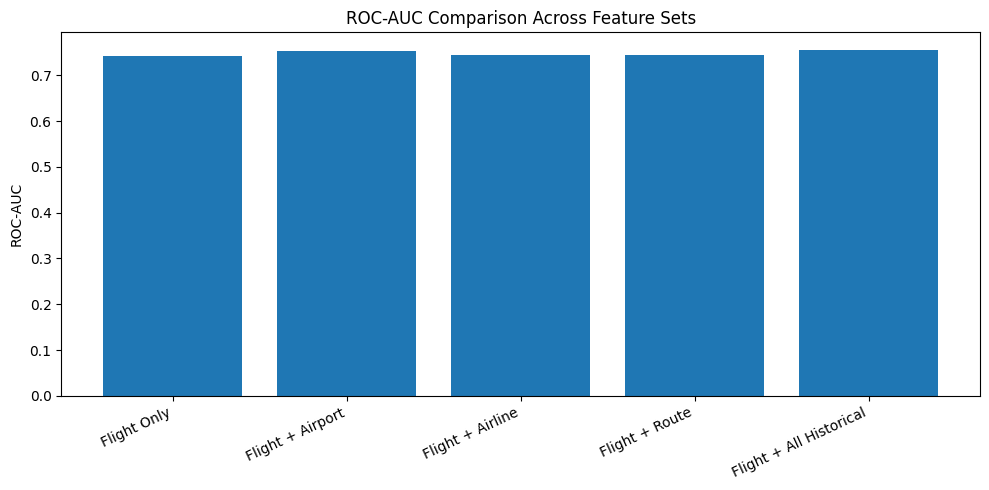

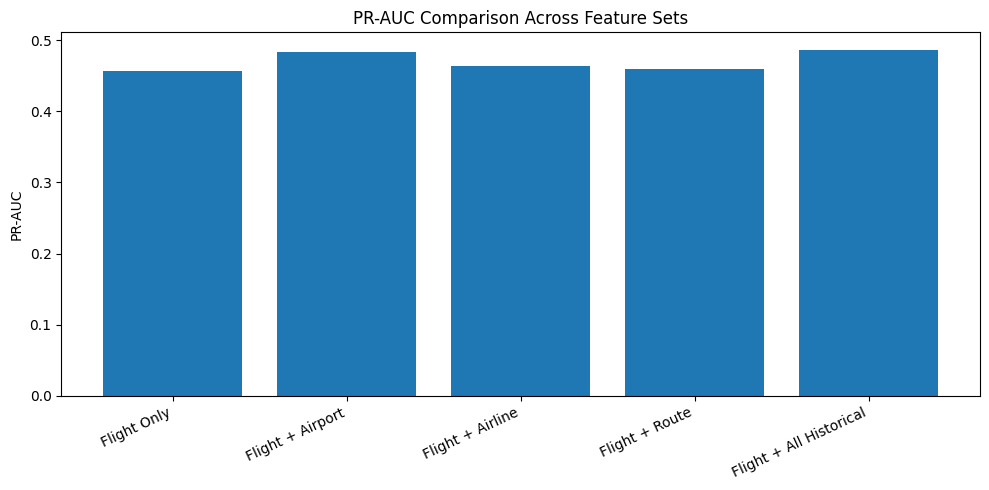

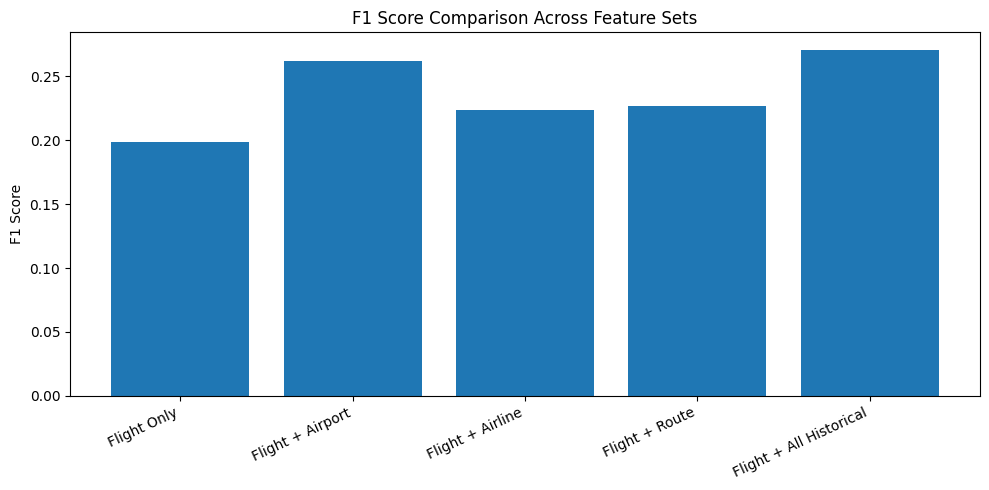

In [101]:
import matplotlib.pyplot as plt

metrics = ["ROC-AUC", "PR-AUC", "F1 Score"]

for metric in metrics:
    plt.figure(figsize=(10, 5))

    plt.bar(results_df["Feature Set"], results_df[metric])

    plt.title(metric + " Comparison Across Feature Sets")
    plt.ylabel(metric)
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

In [102]:
best_result = results_df.loc[results_df["ROC-AUC"].idxmax()]

print("Best Feature Configuration:", best_result["Feature Set"])
print("ROC-AUC:", best_result["ROC-AUC"])
print("PR-AUC:", best_result["PR-AUC"])
print("F1 Score:", best_result["F1 Score"])
print("Brier Score:", best_result["Brier Score"])


Best Feature Configuration: Flight + All Historical
ROC-AUC: 0.7558797962278259
PR-AUC: 0.4866812536162134
F1 Score: 0.2709657068180794
Brier Score: 0.1341947317123413


In [103]:
from sklearn.model_selection import train_test_split

best_features = feature_sets["Flight + All Historical"]

X_model_train, X_cal, y_model_train, y_cal = train_test_split(
    X_train[best_features],
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Model training:", X_model_train.shape)
print("Calibration:", X_cal.shape)
print("Final testing:", X_test[best_features].shape)

Model training: (668642, 27)
Calibration: (167161, 27)
Final testing: (358202, 27)


In [104]:
best_preprocessor = create_preprocessor(best_features)

X_model_encoded = best_preprocessor.fit_transform(X_model_train)
X_cal_encoded = best_preprocessor.transform(X_cal)
X_test_encoded = best_preprocessor.transform(X_test[best_features])

final_model = XGBClassifier(**model_settings)

final_model.fit(X_model_encoded, y_model_train)

raw_cal_probs = final_model.predict_proba(X_cal_encoded)[:, 1]
raw_test_probs = final_model.predict_proba(X_test_encoded)[:, 1]

print("Model training completed.")
print("Calibration probabilities:", len(raw_cal_probs))
print("Test probabilities:", len(raw_test_probs))

Model training completed.
Calibration probabilities: 167161
Test probabilities: 358202


In [105]:
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression

# Platt Scaling
platt_model = LogisticRegression()
platt_model.fit(raw_cal_probs.reshape(-1, 1), y_cal)

platt_test_probs = platt_model.predict_proba(
    raw_test_probs.reshape(-1, 1)
)[:, 1]

# Isotonic Regression
isotonic_model = IsotonicRegression(out_of_bounds="clip")
isotonic_model.fit(raw_cal_probs, y_cal)

isotonic_test_probs = isotonic_model.predict(raw_test_probs)

print("Platt Scaling completed.")
print("Isotonic Regression completed.")
print("All calibrated probabilities generated.")

Platt Scaling completed.
Isotonic Regression completed.
All calibrated probabilities generated.


In [106]:
from sklearn.metrics import brier_score_loss, log_loss
from sklearn.calibration import calibration_curve

def calculate_ece(y_true, probabilities, bins=10):
    observed, predicted = calibration_curve(
        y_true, probabilities, n_bins=bins, strategy="uniform"
    )

    counts = np.histogram(probabilities, bins=np.linspace(0, 1, bins + 1))[0]
    ece = np.sum(counts * np.abs(observed - predicted)) / len(y_true)

    return ece

calibration_results = []

probability_sets = {
    "Raw XGBoost": raw_test_probs,
    "Platt Scaling": platt_test_probs,
    "Isotonic Regression": isotonic_test_probs
}

for name, probs in probability_sets.items():
    calibration_results.append({
        "Method": name,
        "Brier Score": brier_score_loss(y_test, probs),
        "Log Loss": log_loss(y_test, probs),
        "ECE": calculate_ece(y_test, probs)
    })

calibration_df = pd.DataFrame(calibration_results)
print(calibration_df.round(5).to_string(index=False))

             Method  Brier Score  Log Loss     ECE
        Raw XGBoost      0.13457   0.42837 0.01618
      Platt Scaling      0.13439   0.42873 0.01717
Isotonic Regression      0.13397   0.42684 0.00244


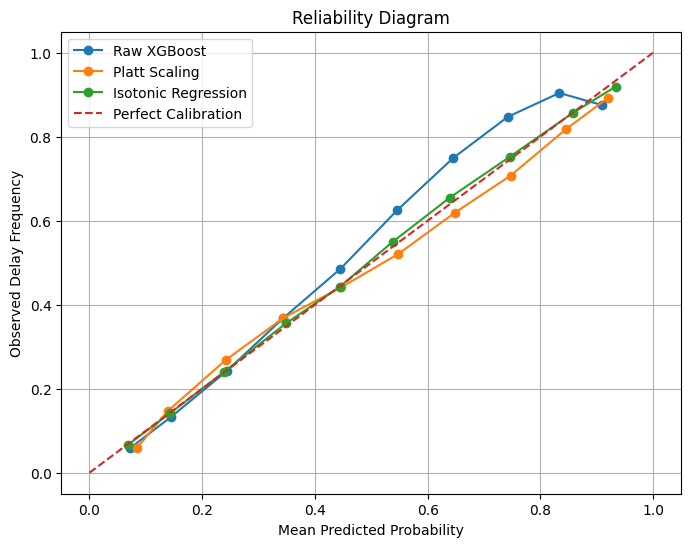

In [107]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for name, probs in probability_sets.items():
    actual, predicted = calibration_curve(
        y_test, probs, n_bins=10, strategy="uniform"
    )

    plt.plot(predicted, actual, marker="o", label=name)

plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect Calibration")
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Delay Frequency")
plt.title("Reliability Diagram")
plt.legend()
plt.grid()
plt.show()

In [108]:
best_calibration = calibration_df.loc[
    calibration_df["Brier Score"].idxmin()
]

print("Best Calibration Method:", best_calibration["Method"])
print("Brier Score:", best_calibration["Brier Score"])
print("Log Loss:", best_calibration["Log Loss"])
print("ECE:", best_calibration["ECE"])

Best Calibration Method: Isotonic Regression
Brier Score: 0.13397110998630524
Log Loss: 0.4268395751196241
ECE: 0.002438825161745403


In [109]:
calibration_probability_sets = {
    "Raw XGBoost": raw_cal_probs,
    "Platt Scaling": platt_model.predict_proba(
        raw_cal_probs.reshape(-1, 1)
    )[:, 1],
    "Isotonic Regression": isotonic_model.predict(raw_cal_probs)
}

cost_ratios = [1, 2, 5, 10, 20]
thresholds = np.arange(0.05, 0.96, 0.01)

cost_results = []

for method, probs in calibration_probability_sets.items():

    for ratio in cost_ratios:

        costs = []

        for threshold in thresholds:
            pred = (probs >= threshold).astype(int)

            fp = np.sum((pred == 1) & (np.array(y_cal) == 0))
            fn = np.sum((pred == 0) & (np.array(y_cal) == 1))

            costs.append((fp + ratio * fn) / len(y_cal))

        best_index = np.argmin(costs)

        cost_results.append({
            "Method": method,
            "FN/FP Cost Ratio": ratio,
            "Best Threshold": thresholds[best_index],
            "Minimum Cost": costs[best_index]
        })

cost_df = pd.DataFrame(cost_results)

print(cost_df.round(4).to_string(index=False))

             Method  FN/FP Cost Ratio  Best Threshold  Minimum Cost
        Raw XGBoost                 1            0.46        0.1813
        Raw XGBoost                 2            0.33        0.3213
        Raw XGBoost                 5            0.18        0.5713
        Raw XGBoost                10            0.10        0.7224
        Raw XGBoost                20            0.05        0.7883
      Platt Scaling                 1            0.52        0.1812
      Platt Scaling                 2            0.32        0.3213
      Platt Scaling                 5            0.15        0.5709
      Platt Scaling                10            0.10        0.7208
      Platt Scaling                20            0.08        0.7888
Isotonic Regression                 1            0.49        0.1812
Isotonic Regression                 2            0.33        0.3210
Isotonic Regression                 5            0.17        0.5704
Isotonic Regression                10           

In [110]:
test_cost_results = []

for _, row in cost_df.iterrows():

    method = row["Method"]
    ratio = row["FN/FP Cost Ratio"]
    threshold = row["Best Threshold"]

    probs = probability_sets[method]
    pred = (probs >= threshold).astype(int)

    fp = np.sum((pred == 1) & (np.array(y_test) == 0))
    fn = np.sum((pred == 0) & (np.array(y_test) == 1))

    total_cost = fp + ratio * fn

    test_cost_results.append({
        "Method": method,
        "FN/FP Ratio": ratio,
        "Threshold": threshold,
        "False Positives": fp,
        "False Negatives": fn,
        "Expected Cost per Flight": total_cost / len(y_test)
    })

test_cost_df = pd.DataFrame(test_cost_results)

print(test_cost_df.round(4).to_string(index=False))

             Method  FN/FP Ratio  Threshold  False Positives  False Negatives  Expected Cost per Flight
        Raw XGBoost            1       0.46             7525            56895                    0.1798
        Raw XGBoost            2       0.33            24514            44718                    0.3181
        Raw XGBoost            5       0.18           104113            19666                    0.5652
        Raw XGBoost           10       0.10           207622             4899                    0.7164
        Raw XGBoost           20       0.05           274282              363                    0.7860
      Platt Scaling            1       0.52             7811            56580                    0.1798
      Platt Scaling            2       0.32            25386            44281                    0.3181
      Platt Scaling            5       0.15           109189            18580                    0.5642
      Platt Scaling           10       0.10           202817    

Selected Threshold: 0.15000000000000002

Classification Report:
              precision    recall  f1-score   support

         0.0       0.91      0.62      0.74    286488
         1.0       0.33      0.74      0.45     71714

    accuracy                           0.64    358202
   macro avg       0.62      0.68      0.59    358202
weighted avg       0.79      0.64      0.68    358202



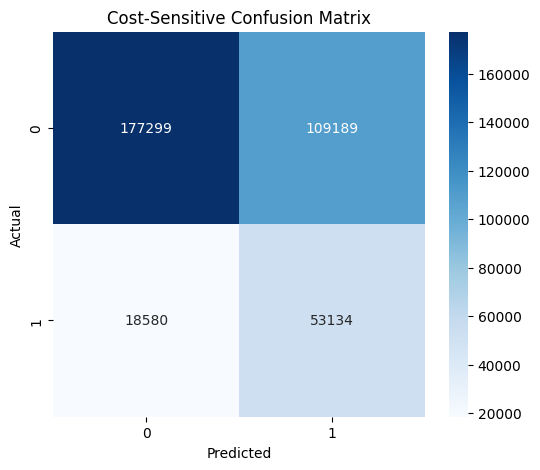

In [111]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

selected = cost_df[
    (cost_df["Method"] == "Platt Scaling") &
    (cost_df["FN/FP Cost Ratio"] == 5)
].iloc[0]

final_threshold = selected["Best Threshold"]

final_predictions = (
    platt_test_probs >= final_threshold
).astype(int)

cm = confusion_matrix(y_test, final_predictions)

print("Selected Threshold:", final_threshold)
print("\nClassification Report:")
print(classification_report(y_test, final_predictions))

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Cost-Sensitive Confusion Matrix")
plt.show()

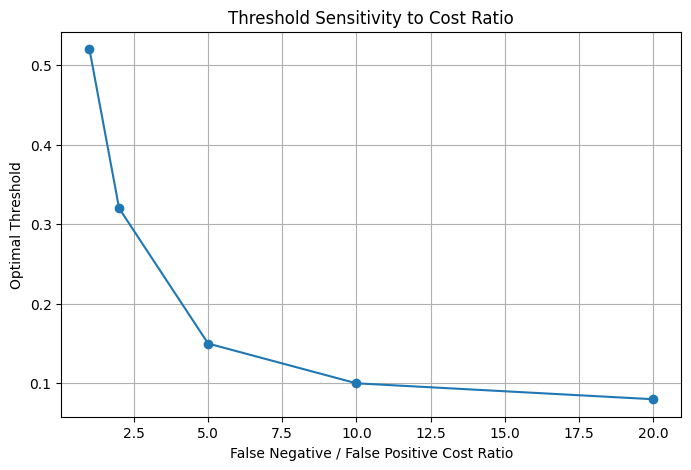

       Method  FN/FP Cost Ratio  Best Threshold  Minimum Cost
Platt Scaling                 1            0.52        0.1812
Platt Scaling                 2            0.32        0.3213
Platt Scaling                 5            0.15        0.5709
Platt Scaling                10            0.10        0.7208
Platt Scaling                20            0.08        0.7888


In [112]:
sensitivity = cost_df[
    (cost_df["Method"] == "Platt Scaling")
].copy()

plt.figure(figsize=(8, 5))

plt.plot(
    sensitivity["FN/FP Cost Ratio"],
    sensitivity["Best Threshold"],
    marker="o"
)

plt.xlabel("False Negative / False Positive Cost Ratio")
plt.ylabel("Optimal Threshold")
plt.title("Threshold Sensitivity to Cost Ratio")
plt.grid()
plt.show()

print(sensitivity.round(4).to_string(index=False))

In [113]:
best_feature = results_df.loc[
    results_df["ROC-AUC"].idxmax()
]

best_calibration = calibration_df.loc[
    calibration_df["Brier Score"].idxmin()
]

best_cost = test_cost_df.loc[
    test_cost_df["Expected Cost per Flight"].idxmin()
]

final_summary = pd.DataFrame({
    "Research Component": [
        "Best Feature Configuration",
        "Best Calibration Method",
        "Best Cost-Sensitive Configuration"
    ],
    "Result": [
        best_feature["Feature Set"],
        best_calibration["Method"],
        best_cost["Method"]
    ],
    "Performance": [
        f"ROC-AUC: {best_feature['ROC-AUC']:.4f}",
        f"Brier Score: {best_calibration['Brier Score']:.4f}",
        f"Expected Cost: {best_cost['Expected Cost per Flight']:.4f}"
    ]
})

print(final_summary.to_string(index=False))

               Research Component                  Result           Performance
       Best Feature Configuration Flight + All Historical       ROC-AUC: 0.7559
          Best Calibration Method     Isotonic Regression   Brier Score: 0.1340
Best Cost-Sensitive Configuration           Platt Scaling Expected Cost: 0.1798
